# Trace collection of SCA-Protected Implementation of Ascon128

## Setup Target Board

In [1]:
PLATFORM = 'CWLITEARM'
CRYPTO_TARGET = 'NONE'
SS_VER = 'SS_VER_2_1'

BAUD_RATE = 38400

In [2]:
import chipwhisperer as cw

print("ChipWhisperer version:", cw.__version__)
print(cw.list_devices())

ChipWhisperer version: 6.0.0
[{'name': 'ChipWhisperer-Lite', 'sn': '50203220343043543330353136313030', 'hw_loc': (1, 5)}]


## Detect Chipwhisperer Board

In [3]:
import time
import chipwhisperer as cw

scope = cw.scope()

target_type = cw.targets.SimpleSerial2
try:
    target = cw.target(scope, target_type)
except:
    print("INFO: Caught exception on reconnecting to target - attempting to reconnect to scope first.")
    print("INFO: This is a work-around when USB has died without Python knowing. Ignore errors above this line.")
    scope = cw.scope()
    target = cw.target(scope, target_type)

print("INFO: Found ChipWhisperer😍")

prog = cw.programmers.STM32FProgrammer

time.sleep(0.05)
scope.default_setup()
def reset_target(scope):
    scope.io.nrst = 'low'
    time.sleep(0.05)
    scope.io.nrst = 'high_z'
    time.sleep(0.05)


INFO: Found ChipWhisperer😍
scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 30                       
scope.gain.db                            changed from 5.5                       to 24.8359375               
scope.adc.basic_mode                     changed from low                       to rising_edge              
scope.adc.samples                        changed from 24400                     to 5000                     
scope.adc.trig_count                     changed from 12396591                  to 35710251                 
scope.clock.adc_src                      changed from clkgen_x1                 to clkgen_x4                
scope.clock.adc_freq                     changed from 0                         to 31871807                 
scope.clock.adc_rate                     changed from 0.0                       to 31871807.0        

### Setup Target Algorithm

In [4]:
CRYPTO_PATH = 'crypto_aead/ascon128v12/protected_bi32_armv6'
DATA_LEN = 190
RESP_LEN = 96
n_shares = 2
SS_SHARED = 1
NUM_SHARES_KEY = n_shares
NUM_SHARES_NPUB = n_shares
NUM_SHARES_AD = n_shares
NUM_SHARES_M = n_shares
NUM_SHARES_C = n_shares
ASCON_ROR_SHARES = 5
ASCON_EXTERN_BI = 0
ASCON_PA_ROUNDS = 12
ASCON_PB_ROUNDS = 6

In [5]:
EXTRA_OPTS = ' -DNUM_SHARES_KEY=' + str(NUM_SHARES_KEY)
EXTRA_OPTS += ' -DNUM_SHARES_NPUB=' + str(NUM_SHARES_NPUB)
EXTRA_OPTS += ' -DNUM_SHARES_AD=' + str(NUM_SHARES_AD)
EXTRA_OPTS += ' -DNUM_SHARES_M=' + str(NUM_SHARES_M)
EXTRA_OPTS += ' -DNUM_SHARES_C=' + str(NUM_SHARES_C)
EXTRA_OPTS += ' -DASCON_ROR_SHARES=' + str(ASCON_ROR_SHARES)
EXTRA_OPTS += ' -DASCON_EXTERN_BI=' + str(ASCON_EXTERN_BI)
EXTRA_OPTS += ' -DASCON_PA_ROUNDS=' + str(ASCON_PA_ROUNDS)
EXTRA_OPTS += ' -DASCON_PB_ROUNDS=' + str(ASCON_PB_ROUNDS)
EXTRA_OPTS += ' -DSS_SHARED=' + str(SS_SHARED)
EXTRA_OPTS += ' -DDATA_LEN=' + str(DATA_LEN)
EXTRA_OPTS += ' -DRESP_LEN=' + str(RESP_LEN)

## Compile

In [13]:
import os

print("Current working directory:", os.getcwd())
print("ChipWhisperer path:", repr(PATH_TO_YOUR_CHIPWHISPERER_FOLDER) if "PATH_TO_YOUR_CHIPWHISPERER_FOLDER" in globals() else "NOT DEFINED")
print("SimpleSerial version:", SS_VER if "SS_VER" in globals() else "NOT DEFINED")

Current working directory: /home/shravani-s-p/Downloads/chipwhisperer
ChipWhisperer path: '../../'
SimpleSerial version: SS_VER_2_1


In [14]:
from pathlib import Path

root = Path("/home/shravani-s-p/Downloads/chipwhisperer")

print("Repository exists:", root.is_dir())
print("Firmware source exists:",
      (root / "hardware/victims/firmware/simpleserial-ascon").is_dir())
print("Firmware Makefile exists:",
      (root / "hardware/victims/firmware/simpleserial-ascon/Makefile").is_file())
print("Notebook path variable:", repr(PATH_TO_YOUR_CHIPWHISPERER_FOLDER))

Repository exists: True
Firmware source exists: True
Firmware Makefile exists: False
Notebook path variable: '../../'


In [15]:
from pathlib import Path

root = Path("/home/shravani-s-p/Downloads/chipwhisperer")
project = root / "hardware/victims/firmware/simpleserial-ascon"

print("Project directory:", project)
print("Project exists:", project.is_dir())

print("\nFiles in project directory:")
if project.is_dir():
    for item in sorted(project.iterdir()):
        print(item.name)

print("\nMakefiles inside project:")
if project.is_dir():
    for item in project.rglob("Makefile"):
        print(item)

Project directory: /home/shravani-s-p/Downloads/chipwhisperer/hardware/victims/firmware/simpleserial-ascon
Project exists: True

Files in project directory:
.dep
Implementations
LICENSE
README.md
crypto_aead.h
makefile
objdir
objdir-$PLATFORM
objdir-CWLITEARM
randombytes.c
randombytes.h
simpleserial-ascon-CWLITEARM.bin
simpleserial-ascon-CWLITEARM.eep
simpleserial-ascon-CWLITEARM.elf
simpleserial-ascon-CWLITEARM.hex
simpleserial-ascon-CWLITEARM.lss
simpleserial-ascon-CWLITEARM.map
simpleserial-ascon-CWLITEARM.sym
simpleserial-ascon.c

Makefiles inside project:


In [6]:
PATH_TO_YOUR_CHIPWHISPERER_FOLDER = '/home/shravani-s-p/Downloads/chipwhisperer'

In [7]:
%%bash -s "$SS_VER" "$PLATFORM" "$CRYPTO_TARGET" "$CRYPTO_PATH" "$EXTRA_OPTS"

set -e

NOTEBOOK_DIR="$PWD"
PROJECT_DIR="/home/shravani-s-p/Downloads/chipwhisperer/hardware/victims/firmware/simpleserial-ascon"

echo "Notebook working directory: $NOTEBOOK_DIR"
echo "Firmware project directory: $PROJECT_DIR"
echo "SimpleSerial version: $1"
echo "Platform: $2"
echo "Crypto target: $3"
echo "Crypto path: $4"
echo "Extra options: $5"

if [ ! -f "$PROJECT_DIR/makefile" ]; then
    echo "ERROR: Firmware makefile not found."
    exit 1
fi

cd "$PROJECT_DIR"

rm -rf "objdir-$2/Implementations/$4" \
       "objdir/Implementations/$4" \
       objdir \
       .dep

mkdir -p "objdir-$2/Implementations/$4" \
         "objdir/Implementations/$4"

make SS_VER="$1" \
     PLATFORM="$2" \
     CRYPTO_TARGET="$3" \
     CRYPTO_PATH="$4" \
     EXTRA_OPTS="$5"

cp "simpleserial-ascon-$2.hex" "$NOTEBOOK_DIR/simpleserial-ascon-$2.hex"

echo "SUCCESS: Firmware built and HEX file copied."

Notebook working directory: /home/shravani-s-p/Downloads/chipwhisperer
Firmware project directory: /home/shravani-s-p/Downloads/chipwhisperer/hardware/victims/firmware/simpleserial-ascon
SimpleSerial version: SS_VER_2_1
Platform: CWLITEARM
Crypto target: NONE
Crypto path: crypto_aead/ascon128v12/protected_bi32_armv6
Extra options:  -DNUM_SHARES_KEY=2 -DNUM_SHARES_NPUB=2 -DNUM_SHARES_AD=2 -DNUM_SHARES_M=2 -DNUM_SHARES_C=2 -DASCON_ROR_SHARES=5 -DASCON_EXTERN_BI=0 -DASCON_PA_ROUNDS=12 -DASCON_PB_ROUNDS=6 -DSS_SHARED=1 -DDATA_LEN=190 -DRESP_LEN=96
Building for platform CWLITEARM with CRYPTO_TARGET=NONE
SS_VER set to SS_VER_2_1
make clean_objs .dep 
make[1]: Entering directory '/home/shravani-s-p/Downloads/chipwhisperer/hardware/victims/firmware/simpleserial-ascon'
Building for platform CWLITEARM with CRYPTO_TARGET=NONE
SS_VER set to SS_VER_2_1
rm -f -- simpleserial-ascon-CWLITEARM.hex
rm -f -- simpleserial-ascon-CWLITEARM.eep
rm -f -- simpleserial-ascon-CWLITEARM.cof
rm -f -- simpleserial-

In file included from Implementations/crypto_aead/ascon128v12/protected_bi32_armv6/crypto_aead_shared.h:1,
                 from simpleserial-ascon.c:35:
Implementations/crypto_aead/ascon128v12/protected_bi32_armv6/shares.h:10:9: warning: "NUM_WORDS" redefined
   10 | #define NUM_WORDS(len) ((((len) + 7) / 8) * 2)
      |         ^~~~~~~~~
simpleserial-ascon.c:32:9: note: this is the location of the previous definition
   32 | #define NUM_WORDS(len) (len)
      |         ^~~~~~~~~


.
Compiling C: randombytes.c
arm-none-eabi-gcc -c -mcpu=cortex-m4 -I. -DNUM_SHARES_KEY=2 -DNUM_SHARES_NPUB=2 -DNUM_SHARES_AD=2 -DNUM_SHARES_M=2 -DNUM_SHARES_C=2 -DASCON_ROR_SHARES=5 -DASCON_EXTERN_BI=0 -DASCON_PA_ROUNDS=12 -DASCON_PB_ROUNDS=6 -DSS_SHARED=1 -DDATA_LEN=190 -DRESP_LEN=96 -mthumb -mfloat-abi=soft -fmessage-length=0 -ffunction-sections -gdwarf-2 -DSS_VER=SS_VER_2_1 -DSTM32F303xC -DSTM32F3 -DSTM32 -DDEBUG -DHAL_TYPE=HAL_stm32f3 -DPLATFORM=CWLITEARM -DF_CPU=7372800UL -DSS_VER_2_0=2 -DSS_VER_2_1=3 -DSS_VER_1_1=1 -DSS_VER_1_0=0 -Os -funsigned-char -funsigned-bitfields -fshort-enums -Wall -Wstrict-prototypes -Wa,-adhlns=objdir-CWLITEARM/randombytes.lst -IImplementations/crypto_aead/ascon128v12/protected_bi32_armv6 -I.././simpleserial/ -I.././hal -I.././hal/stm32f3 -I.././hal/stm32f3/CMSIS -I.././hal/stm32f3/CMSIS/core -I.././hal/stm32f3/CMSIS/device -I.././hal/stm32f4/Legacy -I.././crypto/ -std=gnu99  -MMD -MP -MF .dep/randombytes.o.d randombytes.c -o objdir-CWLITEARM/randombyte

/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-closer.o): in function `_close_r':
/build/newlib-gzz9w0/newlib-4.5.0.20241231/build_nano/arm-none-eabi/thumb/v7e-m/nofp/newlib/../../../../../../newlib/libc/reent/closer.c:47:(.text+0xc): warning: _close is not implemented and will always fail
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-fstatr.o): in function `_fstat_r':
/build/newlib-gzz9w0/newlib-4.5.0.20241231/build_nano/arm-none-eabi/thumb/v7e-m/nofp/newlib/../../../../../../newlib/libc/reent/fstatr.c:55:(.text+0x12): warning: _fstat is not implemented and will always fail
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-signalr.o): in function `

/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-closer.o): note: the message above does not take linker garbage collection into account
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-fstatr.o): note: the message above does not take linker garbage collection into account
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-signalr.o): note: the message above does not take linker garbage collection into account
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-gettimeofdayr.o): note: the message above does not take linker garbage collection into 

/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-signalr.o): in function `_kill_r':
/build/newlib-gzz9w0/newlib-4.5.0.20241231/build_nano/arm-none-eabi/thumb/v7e-m/nofp/newlib/../../../../../../newlib/libc/reent/signalr.c:53:(.text+0x12): warning: _kill is not implemented and will always fail
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-lseekr.o): in function `_lseek_r':
/build/newlib-gzz9w0/newlib-4.5.0.20241231/build_nano/arm-none-eabi/thumb/v7e-m/nofp/newlib/../../../../../../newlib/libc/reent/lseekr.c:49:(.text+0x14): warning: _lseek is not implemented and will always fail
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-readr.o): in function `_

.
Creating load file for Flash: simpleserial-ascon-CWLITEARM.bin
arm-none-eabi-objcopy -O binary -R .eeprom -R .fuse -R .lock -R .signature simpleserial-ascon-CWLITEARM.elf simpleserial-ascon-CWLITEARM.bin
.
Creating load file for EEPROM: simpleserial-ascon-CWLITEARM.eep
arm-none-eabi-objcopy -j .eeprom --set-section-flags=.eeprom="alloc,load" \
--change-section-lma .eeprom=0 --no-change-warnings -O ihex simpleserial-ascon-CWLITEARM.elf simpleserial-ascon-CWLITEARM.eep || exit 0
.
Creating Extended Listing: simpleserial-ascon-CWLITEARM.lss
arm-none-eabi-objdump -h -S -z simpleserial-ascon-CWLITEARM.elf > simpleserial-ascon-CWLITEARM.lss
.
Creating Symbol Table: simpleserial-ascon-CWLITEARM.sym
arm-none-eabi-nm -n simpleserial-ascon-CWLITEARM.elf > simpleserial-ascon-CWLITEARM.sym
Size after:
   text	   data	    bss	    dec	    hex	filename
  19016	    100	   1864	  20980	   51f4	simpleserial-ascon-CWLITEARM.elf
+--------------------------------------------------------
+ Default target 

In [17]:
%%bash -s "$SS_VER" "$PLATFORM" "$CRYPTO_TARGET" "$CRYPTO_PATH" "$EXTRA_OPTS"
export notebook_dir=$PWD
mkdir $PATH_TO_YOUR_CHIPWHISPERER_FOLDER/hardware/victims/firmware/simpleserial-ascon
cp -r simpleserial-ascon $PATH_TO_YOUR_CHIPWHISPERER_FOLDER/hardware/victims/firmware/
cd $PATH_TO_YOUR_CHIPWHISPERER_FOLDER/hardware/victims/firmware/simpleserial-ascon
rm -rf objdir-$2/Implementations/$4 objdir/Implementations/$4 objdir .dep
mkdir -p objdir-$2/Implementations/$4 objdir/Implementations/$4
make SS_VER=$1 PLATFORM=$2 CRYPTO_TARGET=$3 CRYPTO_PATH=$4 EXTRA_OPTS="$5"
cp simpleserial-ascon-$2.hex $notebook_dir/simpleserial-ascon-$2.hex

mkdir: No such file or directory
cp: cannot create directory '/hardware/victims/firmware/': No such file or directory
bash: line 4: cd: /hardware/victims/firmware/simpleserial-ascon: No such file or directory
make: *** No targets specified and no makefile found.  Stop.
cp: 'simpleserial-ascon-CWLITEARM.hex' and '/home/shravani-s-p/Downloads/chipwhisperer/simpleserial-ascon-CWLITEARM.hex' are the same file


CalledProcessError: Command 'b'export notebook_dir=$PWD\nmkdir $PATH_TO_YOUR_CHIPWHISPERER_FOLDER/hardware/victims/firmware/simpleserial-ascon\ncp -r simpleserial-ascon $PATH_TO_YOUR_CHIPWHISPERER_FOLDER/hardware/victims/firmware/\ncd $PATH_TO_YOUR_CHIPWHISPERER_FOLDER/hardware/victims/firmware/simpleserial-ascon\nrm -rf objdir-$2/Implementations/$4 objdir/Implementations/$4 objdir .dep\nmkdir -p objdir-$2/Implementations/$4 objdir/Implementations/$4\nmake SS_VER=$1 PLATFORM=$2 CRYPTO_TARGET=$3 CRYPTO_PATH=$4 EXTRA_OPTS="$5"\ncp simpleserial-ascon-$2.hex $notebook_dir/simpleserial-ascon-$2.hex\n'' returned non-zero exit status 1.

## Flash Binary on the Victim Board

**Note:** If you use a STM32F target board of Revision-02 then you first need to set a specific jumper cable on the UFO board for the following code to work.

For more information have a look here: https://rtfm.newae.com/Targets/UFO%20Targets/CW308T-STM32F/

In [8]:
import os

HEXFILE = "simpleserial-ascon-" + PLATFORM + ".hex"

print("HEX file:", os.path.abspath(HEXFILE))
print("File exists:", os.path.isfile(HEXFILE))
print("Programmer:", prog)

HEX file: /home/shravani-s-p/Downloads/chipwhisperer/simpleserial-ascon-CWLITEARM.hex
File exists: True
Programmer: <class 'chipwhisperer.capture.api.programmers.STM32FProgrammer'>


In [9]:
HEXFILE = "simpleserial-ascon-" + PLATFORM + ".hex"
cw.program_target(scope, prog, HEXFILE)

Detected known STMF32: STM32F302xB(C)/303xB(C)
Extended erase (0x44), this can take ten seconds or more
Attempting to program 19123 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 19123 bytes


## Interface Constants

In [10]:
import numpy as np
import random

# Command
CMD_ASCON = 'a'
CMD_ECHO_TEST = 'e'

# Flags
M = 0x01              # data contains message 
C = 0x02              # data contains ciphertext
A = 0x04              # data contains associated data
N = 0x08              # data contains nonce
K = 0x10              # data contains key
RUN_ENC = 0x20        # run enc after data transmission
RUN_DEC = 0x40        # run dec after data transmission
OMIT_RESULT = 0x80    # omit returning result after encryption/decryption

## Interface Functions

In [11]:
import sys

sys.path.insert(0, "/home/shravani-s-p/Downloads/ascon_helpers_original/helpers")

from ascon_helper import cw_generate_shares as generate_shares
from ascon_helper import cw_combine_shares as combine_shares
from ascon_helper import size_shares

print("Ascon helper functions imported successfully.")

Ascon helper functions imported successfully.


## Test one encryption

In [25]:
print("Target type:", type(target).__name__)
print("Target baud rate:", target.baud)
print("DATA_LEN:", DATA_LEN)
print("RESP_LEN:", RESP_LEN)

Target type: SimpleSerial2
Target baud rate: 230400
DATA_LEN: 190
RESP_LEN: 96


In [26]:
test_m = bytearray.fromhex('00010203')
test_a = bytearray.fromhex('00010203')
test_n = bytearray.fromhex('000102030405060708090a0b0c0d0e0f')
test_k = bytearray.fromhex('000102030405060708090a0b0c0d0e0f')

sm = generate_shares(test_m, NUM_SHARES_M)
sa = generate_shares(test_a, NUM_SHARES_AD)
sn = generate_shares(test_n, NUM_SHARES_NPUB)
sk = generate_shares(test_k, NUM_SHARES_KEY)

print("Message:", len(sm), "bytes")
print("Associated data:", len(sa), "bytes")
print("Nonce:", len(sn), "bytes")
print("Key:", len(sk), "bytes")
print("DATA_LEN:", DATA_LEN)

Message: 16 bytes
Associated data: 16 bytes
Nonce: 32 bytes
Key: 32 bytes
DATA_LEN: 190


In [28]:
# Define input data
m = bytearray.fromhex('00010203')
a = bytearray.fromhex('00010203')
n = bytearray.fromhex('000102030405060708090a0b0c0d0e0f')
k = bytearray.fromhex('000102030405060708090a0b0c0d0e0f')

print("Message length:", len(m))
print("Associated data length:", len(a))
print("Nonce length:", len(n))
print("Key length:", len(k))

Message length: 4
Associated data length: 4
Nonce length: 16
Key length: 16


In [29]:
test_data = bytearray([N | K | M | A | RUN_ENC])
test_data += bytearray([len(m)]) + generate_shares(m, NUM_SHARES_M)
test_data += bytearray([len(a)]) + generate_shares(a, NUM_SHARES_AD)
test_data += generate_shares(n, NUM_SHARES_NPUB)
test_data += generate_shares(k, NUM_SHARES_KEY)

print("Packet before padding:", len(test_data), "bytes")
print("Configured DATA_LEN:", DATA_LEN, "bytes")
print("Fits configured length:", len(test_data) <= DATA_LEN)

Packet before padding: 99 bytes
Configured DATA_LEN: 190 bytes
Fits configured length: True


In [12]:
# Define input data
m = bytearray.fromhex('00010203')
a = bytearray.fromhex('00010203')
n = bytearray.fromhex('000102030405060708090a0b0c0d0e0f')
k = bytearray.fromhex('000102030405060708090a0b0c0d0e0f')

scope.clock.adc_src = 'clkgen_x4'
scope.gain.db = 28

data = bytearray([N|K|M|A|RUN_ENC])
data += bytearray([len(m)]) + generate_shares(m, NUM_SHARES_M)
data += bytearray([len(a)]) + generate_shares(a, NUM_SHARES_AD)
data += generate_shares(n, NUM_SHARES_NPUB)
data += generate_shares(k, NUM_SHARES_KEY)
data += bytearray.fromhex('00'*(DATA_LEN-len(data)))
target.flush()
print('d: ' + ''.join('{:02x}'.format(x) for x in data))
scope.arm()
target.simpleserial_write(CMD_ASCON,data)
scope.capture()
response = target.simpleserial_read('r', RESP_LEN, end='\n', timeout=250, ack=True)

# Extract and print response
mlen = size_shares(len(m), NUM_SHARES_C)
c = combine_shares(response[0:mlen], NUM_SHARES_C)
t = combine_shares(response[mlen:mlen + 16*NUM_SHARES_C], NUM_SHARES_C)
print('c: ' + ''.join('{:02x}'.format(x) for x in c[:len(m)]))
print('t: ' + ''.join('{:02x}'.format(x) for x in t))

scope.adc.samples = scope.adc.trig_count

d: 3d0414a5916b075094460293c401ae054416042c6c71c878b3b0c501fb08de210be427615b63a1bf987599aa23ec2f95a686b4aa7046a08694fa2dedd1b229b19a6fef85e80e9d790bba2ff8655fde64ee9f7993f070dba772faf75fa4f3a15d53b9ea00000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
c: 7763f8ba
t: 02b1e06bc3f2370da5b314302543e9d0


## Set parameters for trace collection

In [13]:
PTlen = 4
CTlen = PTlen
TAGlen = 16
ADlen = 4
Nlen = 16
Klen = 16

# Set fixed parameters
fixed_key       = bytearray(np.random.randint(0,256,Klen, dtype=np.uint8))
fixed_nonce     = bytearray(np.random.randint(0,256,Nlen, dtype=np.uint8))
fixed_ad        = bytearray(np.random.randint(0,256,ADlen, dtype=np.uint8))
fixed_message   = bytearray(np.random.randint(0,256,PTlen, dtype=np.uint8))

In [44]:
# Close the previous trace file if it is still open
try:
    traceFile.close()
    print("Previous trace file closed.")
except Exception as e:
    print("Trace file was already closed or unavailable:", e)

Previous trace file closed.


In [45]:

import trsfile
import sys
import os
import time
import numpy as np
from tqdm import tqdm

COMPRESS_SAMPLES = True

# Start with only 10 traces to test the setup
n_traces = 10

# Create output directory
os.makedirs("traces", exist_ok=True)

# Set scope parameters
samples_per_trace = int(scope.adc.samples)

target.flush()
print("Samples per trace:", samples_per_trace)

if COMPRESS_SAMPLES:
    sample_coding = trsfile.SampleCoding.SHORT
else:
    sample_coding = trsfile.SampleCoding.FLOAT

# Create a new trace file
current_time = time.strftime("%Y%m%d_%H%M%S", time.localtime())

traceFileName = (
    "traces/ASCON_cw_P{}_{}_{}.trs".format(
        n_shares, n_traces, current_time
    )
)

# Define trace parameter sizes
key_size = size_shares(Klen, n_shares)
nonce_size = size_shares(Nlen, n_shares)
plaintext_size = size_shares(PTlen, n_shares)
ad_size = size_shares(ADlen, n_shares)
ciphertext_size = size_shares(CTlen, n_shares)
tag_size = size_shares(TAGlen, n_shares)

headers = {
    trsfile.Header.TRS_VERSION: 2,
    trsfile.Header.DESCRIPTION:
        "Ascon CW masked traces, {} shares".format(n_shares),
    trsfile.Header.NUMBER_SAMPLES: samples_per_trace,
    trsfile.Header.LENGTH_DATA:
        key_size + nonce_size + plaintext_size
        + ad_size + ciphertext_size + tag_size,
    trsfile.Header.SAMPLE_CODING: sample_coding,
    trsfile.Header.LABEL_X: "s",
    trsfile.Header.LABEL_Y: "V",

    trsfile.Header.TRACE_PARAMETER_DEFINITIONS:
        trsfile.parametermap.TraceParameterDefinitionMap({
            "key":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    key_size, 0
                ),
            "nonce":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    nonce_size, key_size
                ),
            "plaintext":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    plaintext_size, key_size + nonce_size
                ),
            "ad":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    ad_size,
                    key_size + nonce_size + plaintext_size
                ),
            "ct":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    ciphertext_size,
                    key_size + nonce_size + plaintext_size + ad_size
                ),
            "tag":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    tag_size,
                    key_size + nonce_size + plaintext_size
                    + ad_size + ciphertext_size
                ),
        }),
}

print("Creating trace file:", traceFileName)

traceFile = trsfile.trs_open(
    traceFileName, mode="w", headers=headers
)

# Main collection loop
start_time = time.time()
completed = 0

try:
    for numTotal in tqdm(range(n_traces), desc="Collecting test traces"):

        flags = M | A | N | K | RUN_ENC
        data = bytearray([flags])

        # Generate input data
        nonce = bytearray(
            np.random.randint(0, 256, Nlen, dtype=np.uint8)
        )
        message = bytearray(
            np.random.randint(0, 256, PTlen, dtype=np.uint8)
        )
        ad = bytearray(
            np.random.randint(0, 256, ADlen, dtype=np.uint8)
        )

        # First half: random keys; second half: fixed key
        if numTotal < n_traces // 2:
            key = bytearray(
                np.random.randint(0, 256, Klen, dtype=np.uint8)
            )
        else:
            key = fixed_key

        # Generate masked shares
        masked_plaintext = generate_shares(message, NUM_SHARES_M)
        masked_ad = generate_shares(ad, NUM_SHARES_AD)
        masked_nonce = generate_shares(nonce, NUM_SHARES_NPUB)
        masked_key = generate_shares(key, NUM_SHARES_KEY)

        # Construct the SimpleSerial command payload
        data += bytearray([len(message)]) + masked_plaintext
        data += bytearray([len(ad)]) + masked_ad
        data += masked_nonce
        data += masked_key

        if len(data) > DATA_LEN:
            raise ValueError(
                "Payload exceeds DATA_LEN: {} > {}".format(
                    len(data), DATA_LEN
                )
            )

        data += bytearray(DATA_LEN - len(data))

        # Capture power trace
        scope.arm()
        target.simpleserial_write(CMD_ASCON, data)

        capture_error = scope.capture()
        if capture_error:
            raise RuntimeError(
                "Scope capture timed out on trace {}".format(numTotal)
            )

        trace = scope.get_last_trace(as_int=COMPRESS_SAMPLES)

        # Read target response
        response = target.simpleserial_read(
            "r", RESP_LEN, end="\n", timeout=250, ack=True
        )

        if response is None or len(response) != RESP_LEN:
            raise RuntimeError(
                "Invalid target response on trace {}: got {} bytes".format(
                    numTotal,
                    0 if response is None else len(response)
                )
            )

        # Split padded ciphertext and tag share blocks
        masked_ct = response[:ciphertext_size]
        masked_tag = response[
            ciphertext_size:ciphertext_size + tag_size
        ]

        if len(masked_ct) != ciphertext_size:
            raise RuntimeError("Incorrect ciphertext-share block size")

        if len(masked_tag) != tag_size:
            raise RuntimeError("Incorrect tag-share block size")

        # Confirm parameter sizes before saving
        parameters = trsfile.parametermap.TraceParameterMap({
            "key": trsfile.parametermap.ByteArrayParameter(masked_key),
            "nonce": trsfile.parametermap.ByteArrayParameter(masked_nonce),
            "plaintext":
                trsfile.parametermap.ByteArrayParameter(masked_plaintext),
            "ad": trsfile.parametermap.ByteArrayParameter(masked_ad),
            "ct": trsfile.parametermap.ByteArrayParameter(masked_ct),
            "tag": trsfile.parametermap.ByteArrayParameter(masked_tag),
        })

        expected_sizes = {
            "key": key_size,
            "nonce": nonce_size,
            "plaintext": plaintext_size,
            "ad": ad_size,
            "ct": ciphertext_size,
            "tag": tag_size,
        }

        for name, expected_size in expected_sizes.items():
            actual_size = len(parameters[name].value)
            if actual_size != expected_size:
                raise ValueError(
                    "{} has size {}, expected {}".format(
                        name, actual_size, expected_size
                    )
                )

        # Save trace and associated parameters
        traceFile.append(
            trsfile.Trace(
                sample_coding,
                trace,
                parameters
            )
        )

        completed += 1

finally:
    traceFile.close()

print("Completed traces:", completed)
print("TRS file:", os.path.abspath(traceFileName))
print("Elapsed time:", time.time() - start_time, "seconds")

Samples per trace: 1440
Creating trace file: traces/ASCON_cw_P2_10_20261029_120545.trs


Completed traces: 10
TRS file: /home/shravani-s-p/Downloads/chipwhisperer/traces/ASCON_cw_P2_10_20261029_120545.trs
Elapsed time: 0.3119039535522461 seconds


File exists: True
File size: 33157 bytes
Number of saved traces: 10
Samples in first trace: 1440
Minimum sample value: 51
Maximum sample value: 725


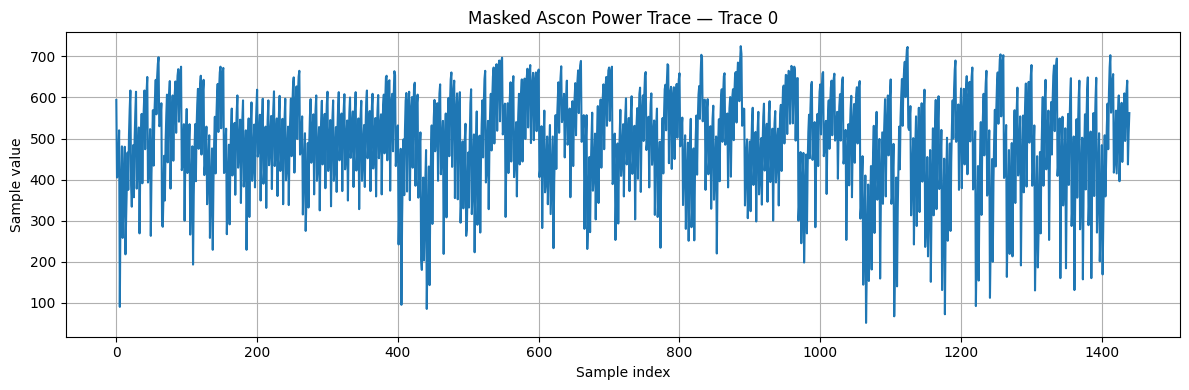

In [46]:
import trsfile
import os
import numpy as np
import matplotlib.pyplot as plt

# Path to the file you just created
trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_10_20261029_120545.trs"
)

# Check that the file exists
print("File exists:", os.path.exists(trace_path))
print("File size:", os.path.getsize(trace_path), "bytes")

# Open and inspect the saved traces
with trsfile.open(trace_path, "r") as traces:
    print("Number of saved traces:", len(traces))

    # Inspect the first trace
    first_trace = traces[0]
    samples = np.asarray(first_trace)

    print("Samples in first trace:", len(samples))
    print("Minimum sample value:", np.min(samples))
    print("Maximum sample value:", np.max(samples))

    # Plot the first waveform
    plt.figure(figsize=(12, 4))
    plt.plot(samples)
    plt.title("Masked Ascon Power Trace — Trace 0")
    plt.xlabel("Sample index")
    plt.ylabel("Sample value")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Trace array shape: (10, 1440)
Minimum sample value: 21
Maximum sample value: 741


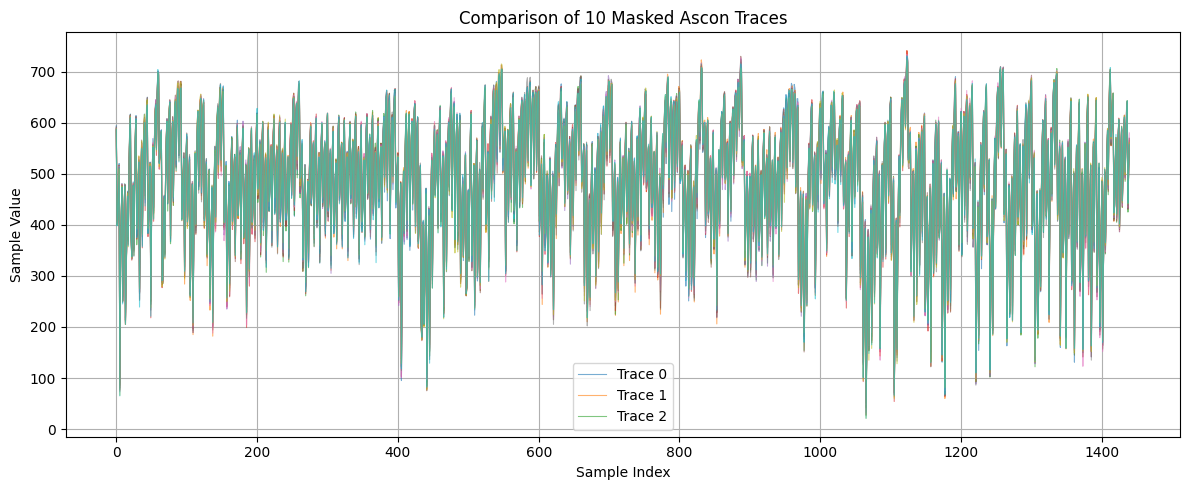

In [47]:
import trsfile
import numpy as np
import matplotlib.pyplot as plt

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_10_20261029_120545.trs"
)

with trsfile.open(trace_path, "r") as traces:
    all_traces = np.array([np.asarray(trace) for trace in traces])

print("Trace array shape:", all_traces.shape)
print("Minimum sample value:", all_traces.min())
print("Maximum sample value:", all_traces.max())

plt.figure(figsize=(12, 5))

for i in range(len(all_traces)):
    plt.plot(all_traces[i], alpha=0.6, linewidth=0.8,
             label=f"Trace {i}" if i < 3 else None)

plt.title("Comparison of 10 Masked Ascon Traces")
plt.xlabel("Sample Index")
plt.ylabel("Sample Value")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Correlation matrix shape: (10, 10)
Mean pairwise correlation: 0.9955296143527753
Minimum pairwise correlation: 0.9939357735984031
Maximum pairwise correlation: 0.9971447201174138


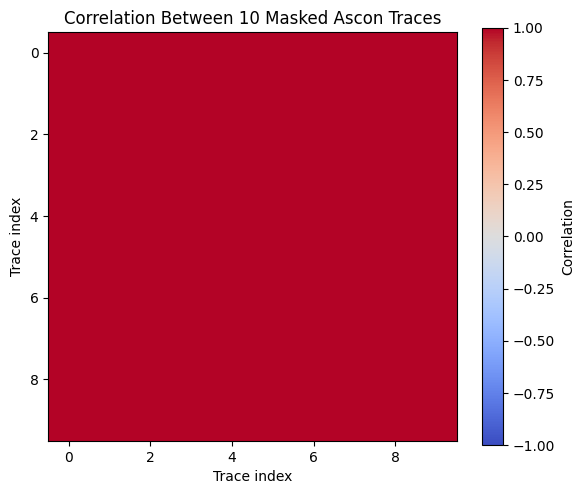

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# all_traces should still contain your 10 traces
correlation_matrix = np.corrcoef(all_traces)

print("Correlation matrix shape:", correlation_matrix.shape)

# Extract correlations between different traces
off_diagonal = correlation_matrix[
    np.triu_indices(len(all_traces), k=1)
]

print("Mean pairwise correlation:", np.mean(off_diagonal))
print("Minimum pairwise correlation:", np.min(off_diagonal))
print("Maximum pairwise correlation:", np.max(off_diagonal))

plt.figure(figsize=(6, 5))
plt.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Correlation")
plt.title("Correlation Between 10 Masked Ascon Traces")
plt.xlabel("Trace index")
plt.ylabel("Trace index")
plt.tight_layout()
plt.show()

In [49]:
import trsfile

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_10_20261029_120545.trs"
)

with trsfile.open(trace_path, "r") as traces:
    print("Total traces:", len(traces))

    for i in range(len(traces)):
        trace = traces[i]
        print(f"\nTrace {i}")

        for name in ["plaintext", "key", "nonce", "ad", "ct", "tag"]:
            try:
                value = trace.get_param(name)
                print(f"{name}: {value}")
            except Exception as e:
                print(f"{name}: unable to read ({e})")

Total traces: 10

Trace 0
plaintext: unable to read ('Trace' object has no attribute 'get_param')
key: unable to read ('Trace' object has no attribute 'get_param')
nonce: unable to read ('Trace' object has no attribute 'get_param')
ad: unable to read ('Trace' object has no attribute 'get_param')
ct: unable to read ('Trace' object has no attribute 'get_param')
tag: unable to read ('Trace' object has no attribute 'get_param')

Trace 1
plaintext: unable to read ('Trace' object has no attribute 'get_param')
key: unable to read ('Trace' object has no attribute 'get_param')
nonce: unable to read ('Trace' object has no attribute 'get_param')
ad: unable to read ('Trace' object has no attribute 'get_param')
ct: unable to read ('Trace' object has no attribute 'get_param')
tag: unable to read ('Trace' object has no attribute 'get_param')

Trace 2
plaintext: unable to read ('Trace' object has no attribute 'get_param')
key: unable to read ('Trace' object has no attribute 'get_param')
nonce: unable 

In [50]:
import trsfile

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_10_20261029_120545.trs"
)

with trsfile.open(trace_path, "r") as traces:
    print("Total traces:", len(traces))

    for i in range(min(3, len(traces))):
        trace = traces[i]

        print(f"\n--- Trace {i} ---")
        print("Available attributes:", [
            name for name in dir(trace)
            if not name.startswith("_")
        ])
        print("Parameters:", trace.parameters)

Total traces: 10

--- Trace 0 ---
Available attributes: ['get_input', 'get_key', 'get_output', 'headers', 'parameters', 'sample_coding', 'samples', 'title']
Parameters: TraceParameterMap({'key': <trsfile.traceparameter.ByteArrayParameter object at 0x7f148d8b6f80>, 'nonce': <trsfile.traceparameter.ByteArrayParameter object at 0x7f148d8b51d0>, 'plaintext': <trsfile.traceparameter.ByteArrayParameter object at 0x7f148d8b5680>, 'ad': <trsfile.traceparameter.ByteArrayParameter object at 0x7f148d8b5b30>, 'ct': <trsfile.traceparameter.ByteArrayParameter object at 0x7f148d8b6990>, 'tag': <trsfile.traceparameter.ByteArrayParameter object at 0x7f148d8b6490>})

--- Trace 1 ---
Available attributes: ['get_input', 'get_key', 'get_output', 'headers', 'parameters', 'sample_coding', 'samples', 'title']
Parameters: TraceParameterMap({'key': <trsfile.traceparameter.ByteArrayParameter object at 0x7f148d8b72f0>, 'nonce': <trsfile.traceparameter.ByteArrayParameter object at 0x7f148d8b73e0>, 'plaintext': <tr

In [51]:
import trsfile

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_10_20261029_120545.trs"
)

with trsfile.open(trace_path, "r") as traces:
    print("Total traces:", len(traces))

    for i in range(min(3, len(traces))):
        trace = traces[i]
        print(f"\n--- Trace {i} ---")

        for name in ["plaintext", "key", "nonce", "ad", "ct", "tag"]:
            param = trace.parameters[name]

            # Inspect the parameter object's available methods
            print(f"{name} parameter type:", type(param).__name__)
            print(f"{name} parameter:", param)

Total traces: 10

--- Trace 0 ---
plaintext parameter type: ByteArrayParameter
plaintext parameter: 0x63E7F772FD8F9DDF5B63226ACBED9CAA
key parameter type: ByteArrayParameter
key parameter: 0xE79A3706E470EDD6EB5D3F3C34780EC6DEECD4D83BBF38EE03DFBEE714AF9B3E
nonce parameter type: ByteArrayParameter
nonce parameter: 0x4AF9C3EF0E5F0EF9D7359DAA1BF3ECB68C0ECD7C00FE96A97165A8D9CB76CB62
ad parameter type: ByteArrayParameter
ad parameter: 0x95ADC566CB56B61621877C8D9B9135A9
ct parameter type: ByteArrayParameter
ct parameter: 0xC335BD31B8A0C3835D0A1C7FE132E094
tag parameter type: ByteArrayParameter
tag parameter: 0x41CA5F1A63BED5ECECFB6D12F3769B76B0469926FA1351CBCD7EDAC073747C78

--- Trace 1 ---
plaintext parameter type: ByteArrayParameter
plaintext parameter: 0x4D4C3B89933531EDAA2EA35F241EACAB
key parameter type: ByteArrayParameter
key parameter: 0x1B638D004CF36F2A072AC9ED6AB46CB2C259CCB52D645148DFEEE71D4A633D3F
nonce parameter type: ByteArrayParameter
nonce parameter: 0x27A25C6BF4233FABC7FE69BE5

In [53]:
import trsfile

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_10_20261029_120545.trs"
)

with trsfile.open(trace_path, "r") as traces:
    print("Total traces:", len(traces))

    for i, trace in enumerate(traces):
        print(f"\nTrace {i}")

        for name in ["plaintext", "key", "nonce", "ad", "ct", "tag"]:
            param = trace.parameters[name]
            print(f"{name}: {len(param)} bytes")

        print("Key:", trace.parameters["key"])
        print("Plaintext:", trace.parameters["plaintext"])

Total traces: 10

Trace 0
plaintext: 16 bytes
key: 32 bytes
nonce: 32 bytes
ad: 16 bytes
ct: 16 bytes
tag: 32 bytes
Key: 0xE79A3706E470EDD6EB5D3F3C34780EC6DEECD4D83BBF38EE03DFBEE714AF9B3E
Plaintext: 0x63E7F772FD8F9DDF5B63226ACBED9CAA

Trace 1
plaintext: 16 bytes
key: 32 bytes
nonce: 32 bytes
ad: 16 bytes
ct: 16 bytes
tag: 32 bytes
Key: 0x1B638D004CF36F2A072AC9ED6AB46CB2C259CCB52D645148DFEEE71D4A633D3F
Plaintext: 0x4D4C3B89933531EDAA2EA35F241EACAB

Trace 2
plaintext: 16 bytes
key: 32 bytes
nonce: 32 bytes
ad: 16 bytes
ct: 16 bytes
tag: 32 bytes
Key: 0x4DF53CF5EFA4CBDCB769C947FE9B5B973DF32754537066203BA7007993D38A70
Plaintext: 0x693622BC0EA6D9882FA420BAF006100F

Trace 3
plaintext: 16 bytes
key: 32 bytes
nonce: 32 bytes
ad: 16 bytes
ct: 16 bytes
tag: 32 bytes
Key: 0xF636935AADD57BCFF75683A50AF02DE0EA8FEF7CC15BA7027B42DD2B599BB546
Plaintext: 0x8B6FF972272EBEE5F0C5F86FCB75FBBE

Trace 4
plaintext: 16 bytes
key: 32 bytes
nonce: 32 bytes
ad: 16 bytes
ct: 16 bytes
tag: 32 bytes
Key: 0x8A056D27C

In [55]:
for name in [
    "n_traces",
    "Klen",
    "Nlen",
    "ADlen",
    "DATA_LEN",
    "RESP_LEN",
    "NUM_SHARES_KEY",
    "NUM_SHARES_NPUB",
    "NUM_SHARES_AD",
    "NUM_SHARES_M",
    "NUM_SHARES_C",
    "key",
    "fixed_key",
    "masked_key",
]:
    if name not in globals():
        print(f"{name}: NOT FOUND")
        continue

    value = globals()[name]

    if isinstance(value, (bytes, bytearray, list, tuple)):
        print(f"{name}: type={type(value).__name__}, length={len(value)}")
        if name in ["key", "fixed_key"]:
            print(f"  value={value.hex()}")
    else:
        print(f"{name}: {value}")

n_traces: 10
Klen: 16
Nlen: 16
ADlen: 4
DATA_LEN: 190
RESP_LEN: 96
NUM_SHARES_KEY: 2
NUM_SHARES_NPUB: 2
NUM_SHARES_AD: 2
NUM_SHARES_M: 2
NUM_SHARES_C: 2
key: type=bytearray, length=16
  value=d5e26c2b4cb716d484385b98f18ea625
fixed_key: type=bytearray, length=16
  value=d5e26c2b4cb716d484385b98f18ea625
masked_key: type=bytearray, length=32


In [15]:

import trsfile
import sys
import os
import time
import numpy as np
from tqdm import tqdm

COMPRESS_SAMPLES = True

# Start with only 10 traces to test the setup
n_traces = 1000

# Create output directory
os.makedirs("traces", exist_ok=True)

# Set scope parameters
samples_per_trace = int(scope.adc.samples)

target.flush()
print("Samples per trace:", samples_per_trace)

if COMPRESS_SAMPLES:
    sample_coding = trsfile.SampleCoding.SHORT
else:
    sample_coding = trsfile.SampleCoding.FLOAT

# Create a new trace file
current_time = time.strftime("%Y%m%d_%H%M%S", time.localtime())

traceFileName = (
    "traces/ASCON_cw_P{}_{}_{}.trs".format(
        n_shares, n_traces, current_time
    )
)

# Define trace parameter sizes
key_size = size_shares(Klen, n_shares)
nonce_size = size_shares(Nlen, n_shares)
plaintext_size = size_shares(PTlen, n_shares)
ad_size = size_shares(ADlen, n_shares)
ciphertext_size = size_shares(CTlen, n_shares)
tag_size = size_shares(TAGlen, n_shares)

headers = {
    trsfile.Header.TRS_VERSION: 2,
    trsfile.Header.DESCRIPTION:
        "Ascon CW masked traces, {} shares".format(n_shares),
    trsfile.Header.NUMBER_SAMPLES: samples_per_trace,
    trsfile.Header.LENGTH_DATA:
        key_size + nonce_size + plaintext_size
        + ad_size + ciphertext_size + tag_size,
    trsfile.Header.SAMPLE_CODING: sample_coding,
    trsfile.Header.LABEL_X: "s",
    trsfile.Header.LABEL_Y: "V",

    trsfile.Header.TRACE_PARAMETER_DEFINITIONS:
        trsfile.parametermap.TraceParameterDefinitionMap({
            "key":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    key_size, 0
                ),
            "nonce":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    nonce_size, key_size
                ),
            "plaintext":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    plaintext_size, key_size + nonce_size
                ),
            "ad":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    ad_size,
                    key_size + nonce_size + plaintext_size
                ),
            "ct":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    ciphertext_size,
                    key_size + nonce_size + plaintext_size + ad_size
                ),
            "tag":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    tag_size,
                    key_size + nonce_size + plaintext_size
                    + ad_size + ciphertext_size
                ),
        }),
}

print("Creating trace file:", traceFileName)

traceFile = trsfile.trs_open(
    traceFileName, mode="w", headers=headers
)

# Main collection loop
start_time = time.time()
completed = 0

try:
    for numTotal in tqdm(range(n_traces), desc="Collecting test traces"):

        flags = M | A | N | K | RUN_ENC
        data = bytearray([flags])

        # Generate input data
        nonce = bytearray(
            np.random.randint(0, 256, Nlen, dtype=np.uint8)
        )
        message = bytearray(
            np.random.randint(0, 256, PTlen, dtype=np.uint8)
        )
        ad = bytearray(
            np.random.randint(0, 256, ADlen, dtype=np.uint8)
        )

        # First half: random keys; second half: fixed key
        if numTotal < n_traces // 2:
            key = bytearray(
                np.random.randint(0, 256, Klen, dtype=np.uint8)
            )
        else:
            key = fixed_key

        # Generate masked shares
        masked_plaintext = generate_shares(message, NUM_SHARES_M)
        masked_ad = generate_shares(ad, NUM_SHARES_AD)
        masked_nonce = generate_shares(nonce, NUM_SHARES_NPUB)
        masked_key = generate_shares(key, NUM_SHARES_KEY)

        # Construct the SimpleSerial command payload
        data += bytearray([len(message)]) + masked_plaintext
        data += bytearray([len(ad)]) + masked_ad
        data += masked_nonce
        data += masked_key

        if len(data) > DATA_LEN:
            raise ValueError(
                "Payload exceeds DATA_LEN: {} > {}".format(
                    len(data), DATA_LEN
                )
            )

        data += bytearray(DATA_LEN - len(data))

        # Capture power trace
        scope.arm()
        target.simpleserial_write(CMD_ASCON, data)

        capture_error = scope.capture()
        if capture_error:
            raise RuntimeError(
                "Scope capture timed out on trace {}".format(numTotal)
            )

        trace = scope.get_last_trace(as_int=COMPRESS_SAMPLES)

        # Read target response
        response = target.simpleserial_read(
            "r", RESP_LEN, end="\n", timeout=250, ack=True
        )

        if response is None or len(response) != RESP_LEN:
            raise RuntimeError(
                "Invalid target response on trace {}: got {} bytes".format(
                    numTotal,
                    0 if response is None else len(response)
                )
            )

        # Split padded ciphertext and tag share blocks
        masked_ct = response[:ciphertext_size]
        masked_tag = response[
            ciphertext_size:ciphertext_size + tag_size
        ]

        if len(masked_ct) != ciphertext_size:
            raise RuntimeError("Incorrect ciphertext-share block size")

        if len(masked_tag) != tag_size:
            raise RuntimeError("Incorrect tag-share block size")

        # Confirm parameter sizes before saving
        parameters = trsfile.parametermap.TraceParameterMap({
            "key": trsfile.parametermap.ByteArrayParameter(masked_key),
            "nonce": trsfile.parametermap.ByteArrayParameter(masked_nonce),
            "plaintext":
                trsfile.parametermap.ByteArrayParameter(masked_plaintext),
            "ad": trsfile.parametermap.ByteArrayParameter(masked_ad),
            "ct": trsfile.parametermap.ByteArrayParameter(masked_ct),
            "tag": trsfile.parametermap.ByteArrayParameter(masked_tag),
        })

        expected_sizes = {
            "key": key_size,
            "nonce": nonce_size,
            "plaintext": plaintext_size,
            "ad": ad_size,
            "ct": ciphertext_size,
            "tag": tag_size,
        }

        for name, expected_size in expected_sizes.items():
            actual_size = len(parameters[name].value)
            if actual_size != expected_size:
                raise ValueError(
                    "{} has size {}, expected {}".format(
                        name, actual_size, expected_size
                    )
                )

        # Save trace and associated parameters
        traceFile.append(
            trsfile.Trace(
                sample_coding,
                trace,
                parameters
            )
        )

        completed += 1

finally:
    traceFile.close()

print("Completed traces:", completed)
print("TRS file:", os.path.abspath(traceFileName))
print("Elapsed time:", time.time() - start_time, "seconds")

Samples per trace: 1440
Creating trace file: traces/ASCON_cw_P2_1000_20261031_154432.trs


Completed traces: 1000
TRS file: /home/shravani-s-p/Downloads/chipwhisperer/traces/ASCON_cw_P2_1000_20261031_154432.trs
Elapsed time: 34.82837510108948 seconds


In [16]:
import trsfile
import numpy as np
import os

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_1000_20261031_154432.trs"
)

print("File exists:", os.path.exists(trace_path))
print("File size (MB):", round(os.path.getsize(trace_path) / (1024 * 1024), 2))

with trsfile.open(trace_path, "r") as traces:
    print("Total traces:", len(traces))

    first = np.asarray(traces[0])
    last = np.asarray(traces[-1])

    print("First trace samples:", len(first))
    print("Last trace samples:", len(last))
    print("First trace range:", first.min(), "to", first.max())
    print("Last trace range:", last.min(), "to", last.max())

    print("Metadata fields:", list(traces[0].parameters.keys()))

File exists: True
File size (MB): 3.13
Total traces: 1000
First trace samples: 1440
Last trace samples: 1440
First trace range: 35 to 734
Last trace range: 20 to 722
Metadata fields: ['key', 'nonce', 'plaintext', 'ad', 'ct', 'tag']


In [17]:
import trsfile

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_1000_20261031_154432.trs"
)

with trsfile.open(trace_path, "r") as traces:
    for i in [0, 1, 2, 498, 499, 500, 501, 998, 999]:
        print(f"Trace {i}:")
        print("Key:", traces[i].parameters["key"])

Trace 0:
Key: 0xAD5F33F27EAB67BFFF90EB1A347A985FE53A9869EED48E3C60A08C294D55EE8C
Trace 1:
Key: 0x336DBC518359155EDEF22CF4FFF5323F0CF099FEA0057665C4E314A4C7378B0C
Trace 2:
Key: 0x527EC389B5CEC241A34F93BC6AF2DC46F6581231EEEEDD51BE0669B6947AD48B
Trace 498:
Key: 0x8A6ED55A73D56D81C0A6C490D6A065CF05CD53A1F162E64DB1BC3A175053EAB0
Trace 499:
Key: 0x0D70934B093A1508BA3EE982C6A91B128B867B8EAAEAAB1FFA5AB1B3D7836953
Trace 500:
Key: 0x663E1A832A037CB1389728AE55EDE2B7E975D6FE6BBF65CCEF3F57C5F67BBCAC
Trace 501:
Key: 0x20DB11FB0918E99EC2B2F166B50475D3BB3EBD8554F448615ED0B90A1BBE0217
Trace 998:
Key: 0xB6933CD2DB41CB2B33E5721211C02ADE2EE8F4FC99A212469B6DE1B9FEABF575
Trace 999:
Key: 0x8478A029948A67580C49ACC1FF3F9AA4A15A06660E9FD88C7D801ADC9531429A


In [18]:
import trsfile
import numpy as np

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_1000_20261031_154432.trs"
)

unmasked_keys = []

with trsfile.open(trace_path, "r") as traces:
    for i in range(len(traces)):
        masked_key = traces[i].parameters["key"].value

        original_key = combine_shares(
            masked_key,
            NUM_SHARES_KEY
        )

        original_key = np.asarray(
            original_key, dtype=np.uint8
        ).tobytes()

        unmasked_keys.append(original_key)

random_key_count = len(set(unmasked_keys[:500]))
fixed_key_count = len(set(unmasked_keys[500:]))

print("Unique original keys in traces 0–499:", random_key_count)
print("Unique original keys in traces 500–999:", fixed_key_count)

print("Trace 500 original key:", unmasked_keys[500].hex())
print("Trace 999 original key:", unmasked_keys[999].hex())

print(
    "All keys in second half identical:",
    len(set(unmasked_keys[500:])) == 1
)

Unique original keys in traces 0–499: 500
Unique original keys in traces 500–999: 1
Trace 500 original key: 64856f83d67661661fbc10f103656c86
Trace 999 original key: 64856f83d67661661fbc10f103656c86
All keys in second half identical: True


In [19]:
import trsfile

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_1000_20261031_154432.trs"
)

with trsfile.open(trace_path, "r") as traces:
    for i in [0, 1, 499, 500, 501, 999]:
        p = traces[i].parameters

        plaintext = combine_shares(
            p["plaintext"].value, NUM_SHARES_M
        )
        nonce = combine_shares(
            p["nonce"].value, NUM_SHARES_NPUB
        )
        ad = combine_shares(
            p["ad"].value, NUM_SHARES_AD
        )

        print(f"\nTrace {i}")
        print("Plaintext:", bytes(plaintext)[:PTlen].hex())
        print("Nonce:", bytes(nonce)[:Nlen].hex())
        print("AD:", bytes(ad)[:ADlen].hex())


Trace 0
Plaintext: 0ce9e0f6
Nonce: e8771d4c644a561f3e2efc2407940981
AD: ee673961

Trace 1
Plaintext: 870dfe05
Nonce: 710409f3cbcc0cbd0446ac21b2e96106
AD: 43fe420b

Trace 499
Plaintext: 5bbf5bb9
Nonce: a0d6fc1c282054b06e632d5a62e4d482
AD: b6d6f521

Trace 500
Plaintext: 70077153
Nonce: 2184406a098fdf4611e8d95e7d346903
AD: 19402dfc

Trace 501
Plaintext: 6c73a747
Nonce: 48fc41a7d481c537db67cbd5fd914485
AD: 661c0519

Trace 999
Plaintext: 1f41485e
Nonce: a8652fecf6387e6aaa09441f3d3b6070
AD: 7406b070


In [20]:
import trsfile
import numpy as np

trace_path = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_1000_20261031_154432.trs"
)

with trsfile.open(trace_path, "r") as traces:
    for i in [0, 1, 499, 500, 501, 999]:
        p = traces[i].parameters

        ct = combine_shares(p["ct"].value, NUM_SHARES_C)
        tag = combine_shares(p["tag"].value, NUM_SHARES_C)

        print(f"\nTrace {i}")
        print("Ciphertext:", bytes(ct)[:CTlen].hex())
        print("Tag:", bytes(tag)[:TAGlen].hex())


Trace 0
Ciphertext: 742754f7
Tag: e09b4342e8aed12162a0bf85ee1563e9

Trace 1
Ciphertext: 4bdfe584
Tag: 6c298cabcd78add686d13a2f1cd242cb

Trace 499
Ciphertext: 7afd9033
Tag: a29234058884324dfa649d4a44b2b758

Trace 500
Ciphertext: 560ee4ac
Tag: 9fe93ef88511ecec3122556416748987

Trace 501
Ciphertext: eaacdecf
Tag: 8c35c7ec7fa9036e3a50cf16fe7edb8a

Trace 999
Ciphertext: d5f609a5
Tag: 3b0d6182991786ba0c8b2c708e5de98f


In [14]:

import trsfile
import sys
import os
import time
import numpy as np
from tqdm import tqdm

COMPRESS_SAMPLES = True

# Start with only 10 traces to test the setup
n_traces = 200000

# Create output directory
os.makedirs("traces", exist_ok=True)

# Set scope parameters
samples_per_trace = int(scope.adc.samples)

target.flush()
print("Samples per trace:", samples_per_trace)

if COMPRESS_SAMPLES:
    sample_coding = trsfile.SampleCoding.SHORT
else:
    sample_coding = trsfile.SampleCoding.FLOAT

# Create a new trace file
current_time = time.strftime("%Y%m%d_%H%M%S", time.localtime())

traceFileName = (
    "traces/ASCON_cw_P{}_{}_{}.trs".format(
        n_shares, n_traces, current_time
    )
)

# Define trace parameter sizes
key_size = size_shares(Klen, n_shares)
nonce_size = size_shares(Nlen, n_shares)
plaintext_size = size_shares(PTlen, n_shares)
ad_size = size_shares(ADlen, n_shares)
ciphertext_size = size_shares(CTlen, n_shares)
tag_size = size_shares(TAGlen, n_shares)

headers = {
    trsfile.Header.TRS_VERSION: 2,
    trsfile.Header.DESCRIPTION:
        "Ascon CW masked traces, {} shares".format(n_shares),
    trsfile.Header.NUMBER_SAMPLES: samples_per_trace,
    trsfile.Header.LENGTH_DATA:
        key_size + nonce_size + plaintext_size
        + ad_size + ciphertext_size + tag_size,
    trsfile.Header.SAMPLE_CODING: sample_coding,
    trsfile.Header.LABEL_X: "s",
    trsfile.Header.LABEL_Y: "V",

    trsfile.Header.TRACE_PARAMETER_DEFINITIONS:
        trsfile.parametermap.TraceParameterDefinitionMap({
            "key":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    key_size, 0
                ),
            "nonce":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    nonce_size, key_size
                ),
            "plaintext":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    plaintext_size, key_size + nonce_size
                ),
            "ad":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    ad_size,
                    key_size + nonce_size + plaintext_size
                ),
            "ct":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    ciphertext_size,
                    key_size + nonce_size + plaintext_size + ad_size
                ),
            "tag":
                trsfile.traceparameter.TraceParameterDefinition(
                    trsfile.traceparameter.ParameterType.BYTE,
                    tag_size,
                    key_size + nonce_size + plaintext_size
                    + ad_size + ciphertext_size
                ),
        }),
}

print("Creating trace file:", traceFileName)

traceFile = trsfile.trs_open(
    traceFileName, mode="w", headers=headers
)

# Main collection loop
start_time = time.time()
completed = 0

try:
    for numTotal in tqdm(range(n_traces), desc="Collecting test traces"):

        flags = M | A | N | K | RUN_ENC
        data = bytearray([flags])

        # Generate input data
        nonce = bytearray(
            np.random.randint(0, 256, Nlen, dtype=np.uint8)
        )
        message = bytearray(
            np.random.randint(0, 256, PTlen, dtype=np.uint8)
        )
        ad = bytearray(
            np.random.randint(0, 256, ADlen, dtype=np.uint8)
        )

        # First half: random keys; second half: fixed key
        if numTotal < n_traces // 2:
            key = bytearray(
                np.random.randint(0, 256, Klen, dtype=np.uint8)
            )
        else:
            key = fixed_key

        # Generate masked shares
        masked_plaintext = generate_shares(message, NUM_SHARES_M)
        masked_ad = generate_shares(ad, NUM_SHARES_AD)
        masked_nonce = generate_shares(nonce, NUM_SHARES_NPUB)
        masked_key = generate_shares(key, NUM_SHARES_KEY)

        # Construct the SimpleSerial command payload
        data += bytearray([len(message)]) + masked_plaintext
        data += bytearray([len(ad)]) + masked_ad
        data += masked_nonce
        data += masked_key

        if len(data) > DATA_LEN:
            raise ValueError(
                "Payload exceeds DATA_LEN: {} > {}".format(
                    len(data), DATA_LEN
                )
            )

        data += bytearray(DATA_LEN - len(data))

        # Capture power trace
        scope.arm()
        target.simpleserial_write(CMD_ASCON, data)

        capture_error = scope.capture()
        if capture_error:
            raise RuntimeError(
                "Scope capture timed out on trace {}".format(numTotal)
            )

        trace = scope.get_last_trace(as_int=COMPRESS_SAMPLES)

        # Read target response
        response = target.simpleserial_read(
            "r", RESP_LEN, end="\n", timeout=250, ack=True
        )

        if response is None or len(response) != RESP_LEN:
            raise RuntimeError(
                "Invalid target response on trace {}: got {} bytes".format(
                    numTotal,
                    0 if response is None else len(response)
                )
            )

        # Split padded ciphertext and tag share blocks
        masked_ct = response[:ciphertext_size]
        masked_tag = response[
            ciphertext_size:ciphertext_size + tag_size
        ]

        if len(masked_ct) != ciphertext_size:
            raise RuntimeError("Incorrect ciphertext-share block size")

        if len(masked_tag) != tag_size:
            raise RuntimeError("Incorrect tag-share block size")

        # Confirm parameter sizes before saving
        parameters = trsfile.parametermap.TraceParameterMap({
            "key": trsfile.parametermap.ByteArrayParameter(masked_key),
            "nonce": trsfile.parametermap.ByteArrayParameter(masked_nonce),
            "plaintext":
                trsfile.parametermap.ByteArrayParameter(masked_plaintext),
            "ad": trsfile.parametermap.ByteArrayParameter(masked_ad),
            "ct": trsfile.parametermap.ByteArrayParameter(masked_ct),
            "tag": trsfile.parametermap.ByteArrayParameter(masked_tag),
        })

        expected_sizes = {
            "key": key_size,
            "nonce": nonce_size,
            "plaintext": plaintext_size,
            "ad": ad_size,
            "ct": ciphertext_size,
            "tag": tag_size,
        }

        for name, expected_size in expected_sizes.items():
            actual_size = len(parameters[name].value)
            if actual_size != expected_size:
                raise ValueError(
                    "{} has size {}, expected {}".format(
                        name, actual_size, expected_size
                    )
                )

        # Save trace and associated parameters
        traceFile.append(
            trsfile.Trace(
                sample_coding,
                trace,
                parameters
            )
        )

        completed += 1

finally:
    traceFile.close()

print("Completed traces:", completed)
print("TRS file:", os.path.abspath(traceFileName))
print("Elapsed time:", time.time() - start_time, "seconds")

Samples per trace: 1440
Creating trace file: traces/ASCON_cw_P2_200000_20261102_160911.trs


Completed traces: 200000
TRS file: /home/shravani-s-p/Downloads/chipwhisperer/traces/ASCON_cw_P2_200000_20261102_160911.trs
Elapsed time: 6511.165542840958 seconds


In [1]:
import os

trs_path = "/home/shravani-s-p/Downloads/chipwhisperer/traces/ASCON_cw_P2_200000_20261102_160911.trs"

print("File exists:", os.path.exists(trs_path))
print("File size (MB):", round(os.path.getsize(trs_path) / (1024 * 1024), 2))

File exists: True
File size (MB): 625.42


In [3]:
import trsfile

trs_path = "/home/shravani-s-p/Downloads/chipwhisperer/traces/ASCON_cw_P2_200000_20261102_160911.trs"

with trsfile.open(trs_path, mode='r') as trs:

    print("Total traces:", len(trs))

    headers = trs.get_headers()

    print("Header sample count:",
          headers.get(trsfile.Header.NUMBER_SAMPLES))

    print("\nChecking selected traces:")

    for i in [0, 1, 99999, 100000, 100001, 199999]:

        trace = trs[i]

        print(f"\nTrace {i}:")
        print("  Samples:", len(trace))
        print("  Parameters:", list(trace.parameters.keys()))

Total traces: 200000
Header sample count: 1440

Checking selected traces:

Trace 0:
  Samples: 1440
  Parameters: ['key', 'nonce', 'plaintext', 'ad', 'ct', 'tag']

Trace 1:
  Samples: 1440
  Parameters: ['key', 'nonce', 'plaintext', 'ad', 'ct', 'tag']

Trace 99999:
  Samples: 1440
  Parameters: ['key', 'nonce', 'plaintext', 'ad', 'ct', 'tag']

Trace 100000:
  Samples: 1440
  Parameters: ['key', 'nonce', 'plaintext', 'ad', 'ct', 'tag']

Trace 100001:
  Samples: 1440
  Parameters: ['key', 'nonce', 'plaintext', 'ad', 'ct', 'tag']

Trace 199999:
  Samples: 1440
  Parameters: ['key', 'nonce', 'plaintext', 'ad', 'ct', 'tag']


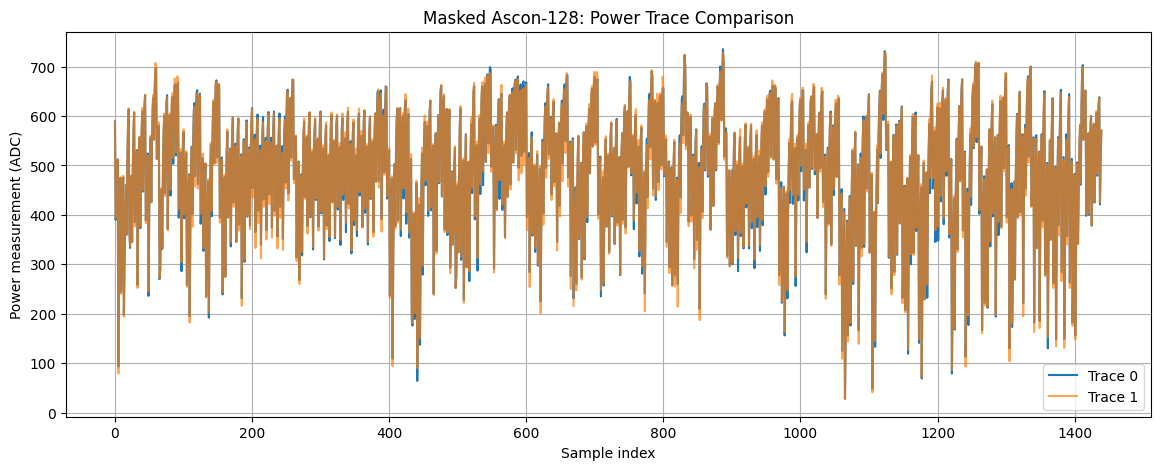

Trace length: 1440
Trace 0 minimum: 28.0
Trace 0 maximum: 735.0
Trace 0 mean: 488.15347
Trace 0 standard deviation: 123.41186


In [4]:
import trsfile
import numpy as np
import matplotlib.pyplot as plt

trs_path = "/home/shravani-s-p/Downloads/chipwhisperer/traces/ASCON_cw_P2_200000_20261102_160911.trs"

with trsfile.open(trs_path, mode='r') as trs:
    trace_0 = np.array(trs[0].samples, dtype=np.float32)
    trace_1 = np.array(trs[1].samples, dtype=np.float32)
    trace_100000 = np.array(trs[100000].samples, dtype=np.float32)

plt.figure(figsize=(14, 5))
plt.plot(trace_0, label="Trace 0")
plt.plot(trace_1, label="Trace 1", alpha=0.7)
plt.xlabel("Sample index")
plt.ylabel("Power measurement (ADC)")
plt.title("Masked Ascon-128: Power Trace Comparison")
plt.legend()
plt.grid()
plt.show()

print("Trace length:", len(trace_0))
print("Trace 0 minimum:", np.min(trace_0))
print("Trace 0 maximum:", np.max(trace_0))
print("Trace 0 mean:", np.mean(trace_0))
print("Trace 0 standard deviation:", np.std(trace_0))

Random-key group shape: (5000, 1440)
Fixed-key group shape: (5000, 1440)


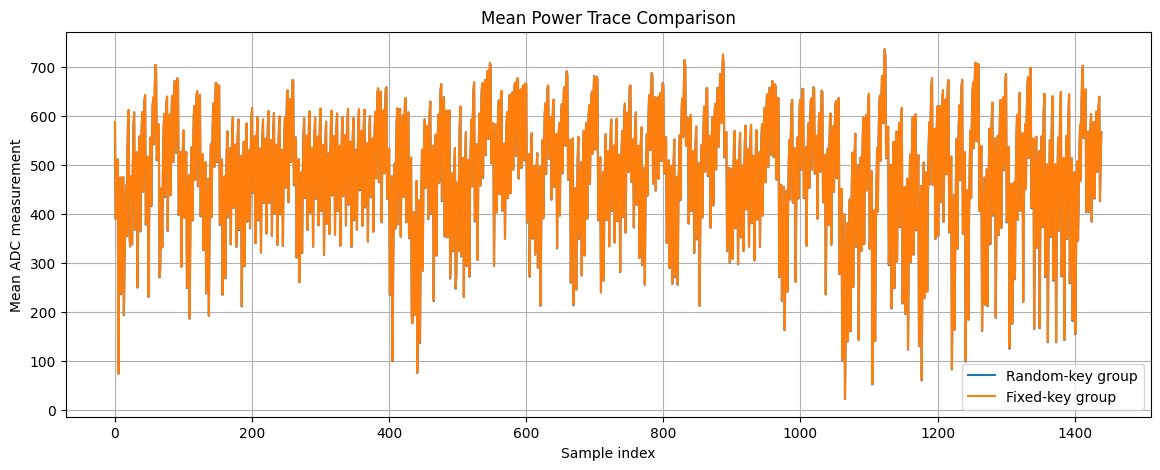

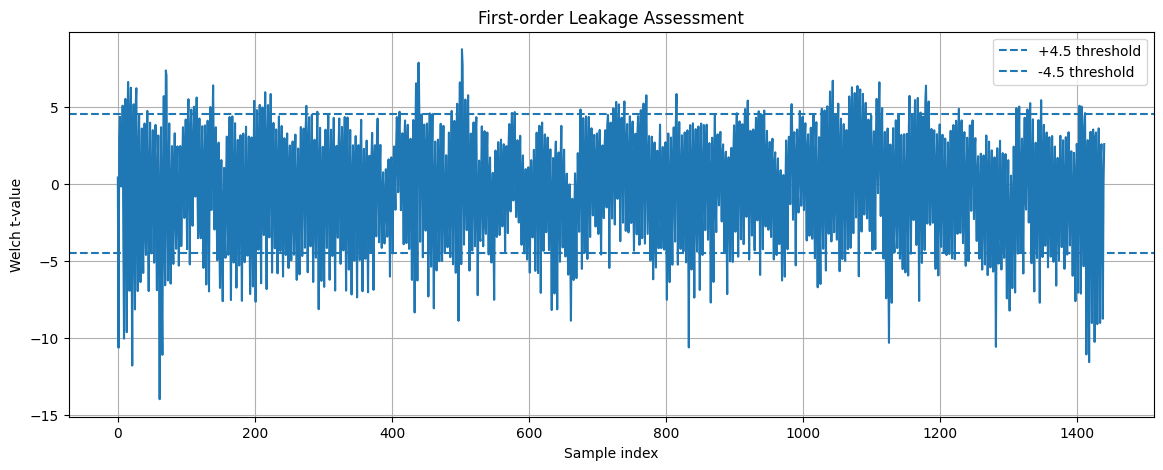

Maximum absolute t-value: 13.9875965
Samples exceeding |t| = 4.5: 300


In [5]:
import trsfile
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

trs_path = "/home/shravani-s-p/Downloads/chipwhisperer/traces/ASCON_cw_P2_200000_20261102_160911.trs"

n = 5000

random_key_traces = []
fixed_key_traces = []

with trsfile.open(trs_path, mode='r') as trs:

    for i in range(n):
        random_key_traces.append(
            np.asarray(trs[i].samples, dtype=np.float32)
        )

    for i in range(100000, 100000 + n):
        fixed_key_traces.append(
            np.asarray(trs[i].samples, dtype=np.float32)
        )

random_key_traces = np.array(random_key_traces)
fixed_key_traces = np.array(fixed_key_traces)

print("Random-key group shape:", random_key_traces.shape)
print("Fixed-key group shape:", fixed_key_traces.shape)

# Calculate mean waveforms
mean_random = np.mean(random_key_traces, axis=0)
mean_fixed = np.mean(fixed_key_traces, axis=0)

# Welch's t-test at each sample
t_values = ttest_ind(
    random_key_traces,
    fixed_key_traces,
    axis=0,
    equal_var=False
).statistic

# Plot mean waveforms
plt.figure(figsize=(14, 5))
plt.plot(mean_random, label="Random-key group")
plt.plot(mean_fixed, label="Fixed-key group")
plt.xlabel("Sample index")
plt.ylabel("Mean ADC measurement")
plt.title("Mean Power Trace Comparison")
plt.legend()
plt.grid()
plt.show()

# Plot t-values
plt.figure(figsize=(14, 5))
plt.plot(t_values)
plt.axhline(4.5, linestyle='--', label="+4.5 threshold")
plt.axhline(-4.5, linestyle='--', label="-4.5 threshold")
plt.xlabel("Sample index")
plt.ylabel("Welch t-value")
plt.title("First-order Leakage Assessment")
plt.legend()
plt.grid()
plt.show()

print("Maximum absolute t-value:", np.nanmax(np.abs(t_values)))
print("Samples exceeding |t| = 4.5:",
      np.sum(np.abs(t_values) > 4.5))

In [6]:
print("Maximum absolute t-value:", np.nanmax(np.abs(t_values)))

print("Samples exceeding |t| = 4.5:",
      np.sum(np.abs(t_values) > 4.5))

Maximum absolute t-value: 13.9875965
Samples exceeding |t| = 4.5: 300


In [7]:
import numpy as np
from scipy.stats import ttest_ind

# Split the two groups into independent halves
random_A = random_key_traces[:2500]
random_B = random_key_traces[2500:]

fixed_A = fixed_key_traces[:2500]
fixed_B = fixed_key_traces[2500:]

# Welch t-tests for each pair
t_A = ttest_ind(
    random_A, fixed_A,
    axis=0, equal_var=False
).statistic

t_B = ttest_ind(
    random_B, fixed_B,
    axis=0, equal_var=False
).statistic

print("Split A maximum |t|:",
      np.nanmax(np.abs(t_A)))

print("Split A threshold crossings:",
      np.sum(np.abs(t_A) > 4.5))

print("Split B maximum |t|:",
      np.nanmax(np.abs(t_B)))

print("Split B threshold crossings:",
      np.sum(np.abs(t_B) > 4.5))

print("Common threshold crossings:",
      np.sum((np.abs(t_A) > 4.5) &
             (np.abs(t_B) > 4.5)))

Split A maximum |t|: 12.179834
Split A threshold crossings: 253
Split B maximum |t|: 8.71018
Split B threshold crossings: 71
Common threshold crossings: 18


Random group: (5000, 1440)
Fixed group: (5000, 1440)
Training traces per group: 2500
Evaluation traces per group: 2500


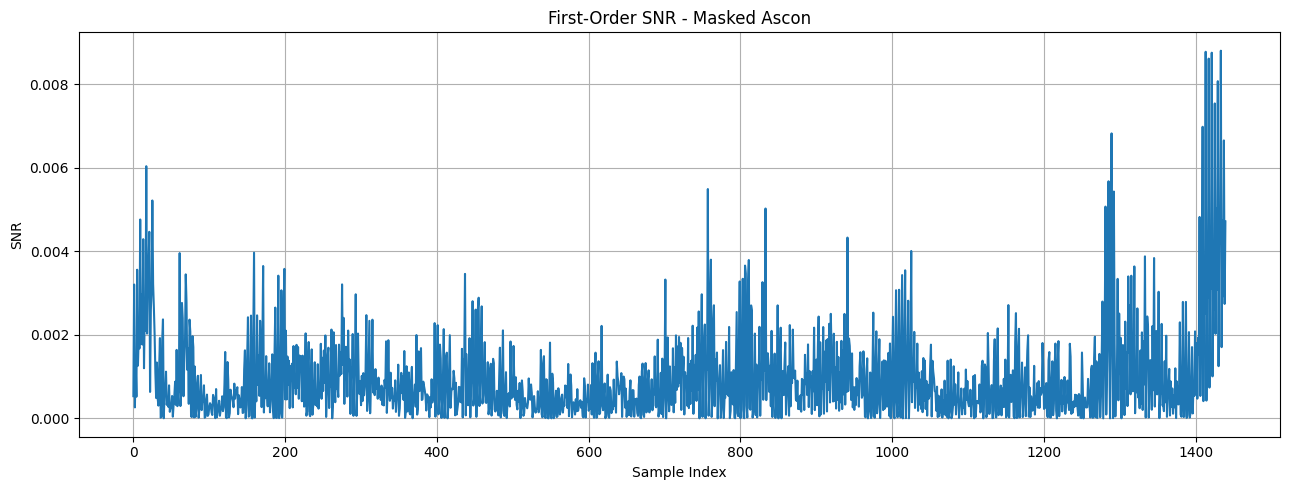

Maximum first-order SNR: 0.008801986
Mean first-order SNR: 0.00097270467


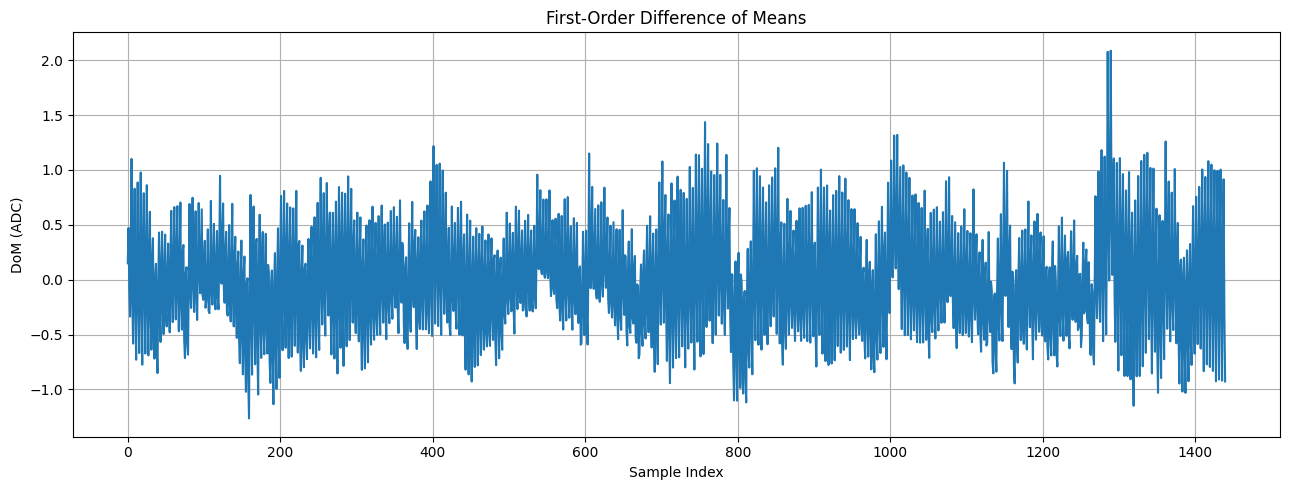

First-order maximum |t|: 6.6326714
First-order threshold crossings: 27


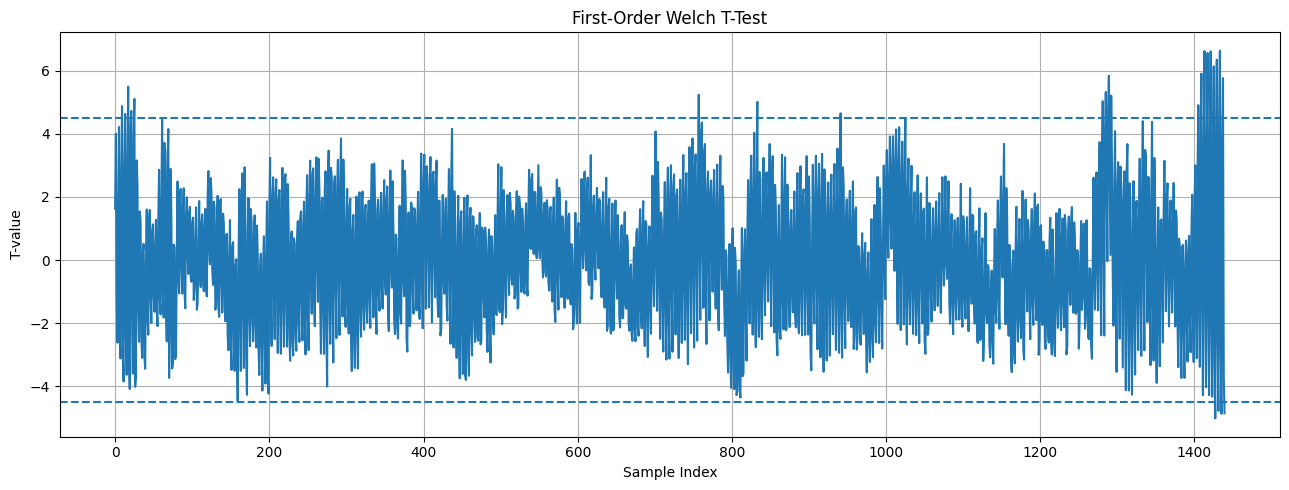

Selected POI: [ 333  453  457  502  571  575 1081 1089]
Second-order feature shape: (2500, 28)
Maximum second-order SNR: 0.0017022364
Mean second-order SNR: 0.0002867606


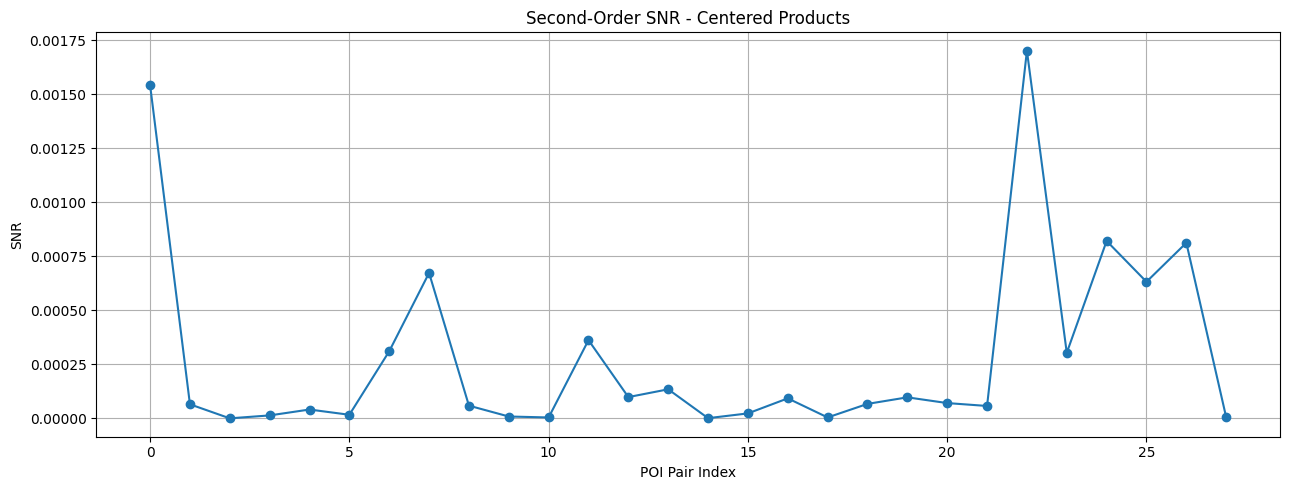

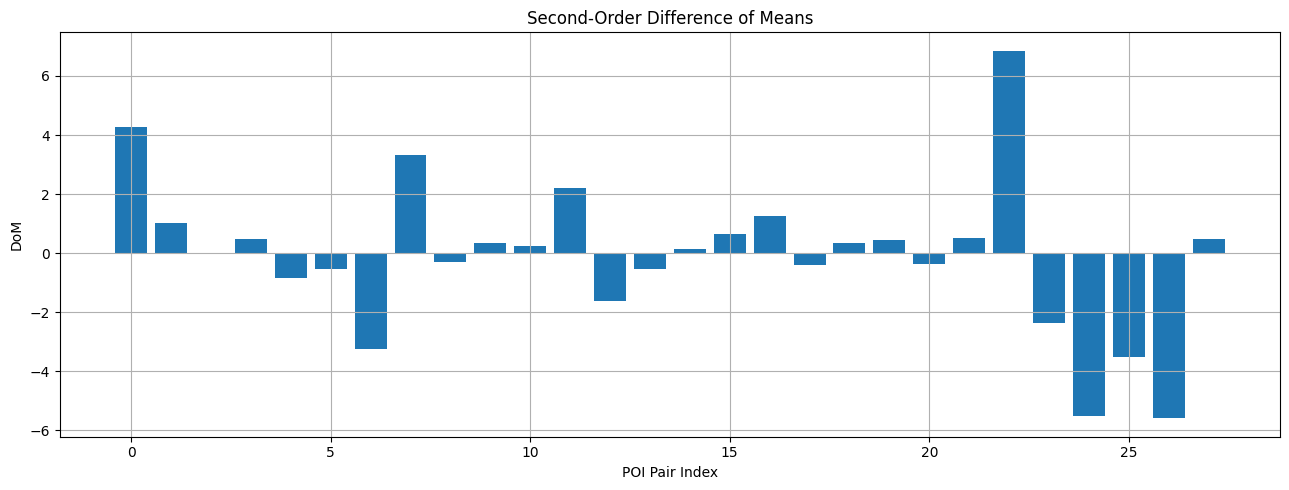

Second-order maximum |t|: 2.9168093
Second-order threshold crossings: 0


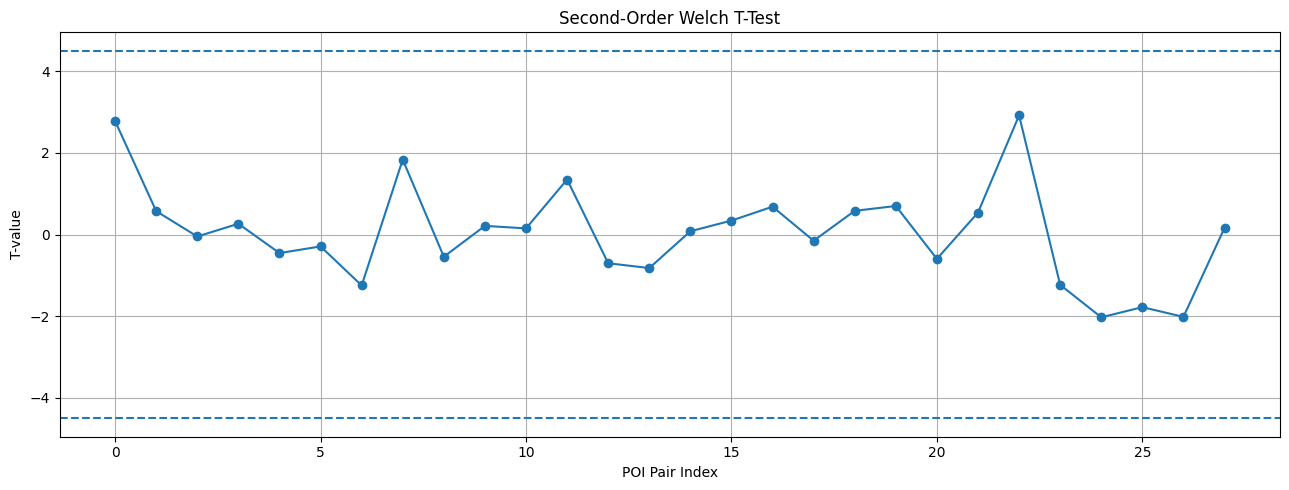


FIRST-ORDER HOTELLING T-SQUARED
T2: 22.02330998243895
F-statistic: 2.7490581263093437
P-value: 0.004995518287197224

SECOND-ORDER HOTELLING T-SQUARED
T2: 34.36895550272585
F-statistic: 1.2208317455843067
P-value: 0.19580717318624064

ANALYSIS COMPLETED


In [8]:
import trsfile
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from itertools import combinations

# ============================================================
# 1. CONFIGURATION
# ============================================================

TRS_PATH = (
    "/home/shravani-s-p/Downloads/chipwhisperer/"
    "traces/ASCON_cw_P2_200000_20261102_160911.trs"
)

TRACES_PER_GROUP = 5000
POI_COUNT = 8
TVLA_THRESHOLD = 4.5

rng = np.random.default_rng(42)

# ============================================================
# 2. LOAD TRACES
# ============================================================

def load_trace_group(traces, start, stop, count):

    indices = np.linspace(
        start, stop - 1, count, dtype=int
    )

    X = np.empty(
        (count, 1440), dtype=np.float32
    )

    for j, idx in enumerate(indices):
        X[j] = np.asarray(
            traces[int(idx)].samples,
            dtype=np.float32
        )

    return X


with trsfile.open(TRS_PATH, mode="r") as trs:

    assert len(trs) == 200000, "Unexpected trace count"

    random_traces = load_trace_group(
        trs, 0, 100000, TRACES_PER_GROUP
    )

    fixed_traces = load_trace_group(
        trs, 100000, 200000, TRACES_PER_GROUP
    )


print("Random group:", random_traces.shape)
print("Fixed group:", fixed_traces.shape)

# ============================================================
# 3. TRAINING AND EVALUATION SPLIT
# ============================================================

def split_data(X):

    indices = rng.permutation(len(X))

    midpoint = len(X) // 2

    train = X[indices[:midpoint]]
    test = X[indices[midpoint:]]

    return train, test


random_train, random_test = split_data(random_traces)
fixed_train, fixed_test = split_data(fixed_traces)

print("Training traces per group:", len(random_train))
print("Evaluation traces per group:", len(random_test))

# ============================================================
# 4. STANDARD SNR FUNCTION
# ============================================================

def calculate_snr(group_a, group_b):

    n_a = len(group_a)
    n_b = len(group_b)

    mean_a = np.mean(group_a, axis=0)
    mean_b = np.mean(group_b, axis=0)

    var_a = np.var(group_a, axis=0)
    var_b = np.var(group_b, axis=0)

    total = n_a + n_b

    grand_mean = (
        n_a * mean_a + n_b * mean_b
    ) / total

    signal = (
        n_a * (mean_a - grand_mean)**2
        + n_b * (mean_b - grand_mean)**2
    ) / total

    noise = (
        n_a * var_a + n_b * var_b
    ) / total

    snr = np.divide(
        signal,
        noise,
        out=np.zeros_like(signal),
        where=noise > 0
    )

    return snr


# ============================================================
# 5. FIRST-ORDER SNR
# ============================================================

snr_first = calculate_snr(
    random_test,
    fixed_test
)

plt.figure(figsize=(13, 5))
plt.plot(snr_first)
plt.title("First-Order SNR - Masked Ascon")
plt.xlabel("Sample Index")
plt.ylabel("SNR")
plt.grid()
plt.tight_layout()
plt.show()

print("Maximum first-order SNR:", np.max(snr_first))
print("Mean first-order SNR:", np.mean(snr_first))

# ============================================================
# 6. FIRST-ORDER DIFFERENCE OF MEANS
# ============================================================

dom_first = (
    np.mean(fixed_test, axis=0)
    - np.mean(random_test, axis=0)
)

plt.figure(figsize=(13, 5))
plt.plot(dom_first)
plt.title("First-Order Difference of Means")
plt.xlabel("Sample Index")
plt.ylabel("DoM (ADC)")
plt.grid()
plt.tight_layout()
plt.show()

# ============================================================
# 7. FIRST-ORDER WELCH T-TEST
# ============================================================

t_first = stats.ttest_ind(
    fixed_test,
    random_test,
    axis=0,
    equal_var=False
).statistic

print("First-order maximum |t|:",
      np.nanmax(np.abs(t_first)))

print("First-order threshold crossings:",
      np.sum(np.abs(t_first) > TVLA_THRESHOLD))

plt.figure(figsize=(13, 5))
plt.plot(t_first)
plt.axhline(TVLA_THRESHOLD, linestyle="--")
plt.axhline(-TVLA_THRESHOLD, linestyle="--")
plt.title("First-Order Welch T-Test")
plt.xlabel("Sample Index")
plt.ylabel("T-value")
plt.grid()
plt.tight_layout()
plt.show()

# ============================================================
# 8. SELECT POINTS OF INTEREST USING TRAINING DATA
# ============================================================

t_train = stats.ttest_ind(
    fixed_train,
    random_train,
    axis=0,
    equal_var=False
).statistic

poi = np.argsort(
    np.nan_to_num(np.abs(t_train), nan=0.0)
)[-POI_COUNT:]

poi = np.sort(poi)

print("Selected POI:", poi)

# ============================================================
# 9. SECOND-ORDER CENTERED PRODUCT TRANSFORMATION
# ============================================================

# Center using training data only
combined_train = np.vstack((
    random_train,
    fixed_train
))

poi_mean = np.mean(
    combined_train[:, poi],
    axis=0
)

pairs = list(combinations(range(POI_COUNT), 2))

def centered_product_transform(X):

    centered = X[:, poi] - poi_mean

    Z = np.empty(
        (len(X), len(pairs)),
        dtype=np.float32
    )

    for k, (i, j) in enumerate(pairs):

        Z[:, k] = (
            centered[:, i] * centered[:, j]
        )

    return Z


random_second = centered_product_transform(
    random_test
)

fixed_second = centered_product_transform(
    fixed_test
)

print("Second-order feature shape:",
      random_second.shape)

# ============================================================
# 10. SECOND-ORDER SNR
# ============================================================

snr_second = calculate_snr(
    random_second,
    fixed_second
)

print("Maximum second-order SNR:",
      np.max(snr_second))

print("Mean second-order SNR:",
      np.mean(snr_second))

plt.figure(figsize=(13, 5))
plt.plot(snr_second, marker="o")
plt.title("Second-Order SNR - Centered Products")
plt.xlabel("POI Pair Index")
plt.ylabel("SNR")
plt.grid()
plt.tight_layout()
plt.show()

# ============================================================
# 11. SECOND-ORDER DIFFERENCE OF MEANS
# ============================================================

dom_second = (
    np.mean(fixed_second, axis=0)
    - np.mean(random_second, axis=0)
)

plt.figure(figsize=(13, 5))
plt.bar(range(len(pairs)), dom_second)
plt.title("Second-Order Difference of Means")
plt.xlabel("POI Pair Index")
plt.ylabel("DoM")
plt.grid()
plt.tight_layout()
plt.show()

# ============================================================
# 12. SECOND-ORDER WELCH T-TEST
# ============================================================

t_second = stats.ttest_ind(
    fixed_second,
    random_second,
    axis=0,
    equal_var=False
).statistic

print("Second-order maximum |t|:",
      np.nanmax(np.abs(t_second)))

print("Second-order threshold crossings:",
      np.sum(np.abs(t_second) > TVLA_THRESHOLD))

plt.figure(figsize=(13, 5))
plt.plot(t_second, marker="o")
plt.axhline(TVLA_THRESHOLD, linestyle="--")
plt.axhline(-TVLA_THRESHOLD, linestyle="--")
plt.title("Second-Order Welch T-Test")
plt.xlabel("POI Pair Index")
plt.ylabel("T-value")
plt.grid()
plt.tight_layout()
plt.show()

# ============================================================
# 13. HOTELLING T-SQUARED TEST
# ============================================================

def hotelling_t2(group_a, group_b):

    n1, p = group_a.shape
    n2, p2 = group_b.shape

    if p != p2:
        raise ValueError("Feature dimensions do not match")

    if n1 + n2 <= p + 1:
        raise ValueError("Insufficient observations")

    mean_a = np.mean(group_a, axis=0)
    mean_b = np.mean(group_b, axis=0)

    covariance_a = np.cov(
        group_a, rowvar=False
    )

    covariance_b = np.cov(
        group_b, rowvar=False
    )

    pooled_covariance = (
        (n1 - 1) * covariance_a
        + (n2 - 1) * covariance_b
    ) / (n1 + n2 - 2)

    difference = mean_a - mean_b

    # Solve covariance * x = difference
    try:
        solution = np.linalg.solve(
            pooled_covariance,
            difference
        )
    except np.linalg.LinAlgError:
        raise ValueError(
            "Covariance matrix is singular. "
            "Reduce POI_COUNT."
        )

    T2 = (
        (n1 * n2) / (n1 + n2)
    ) * np.dot(difference, solution)

    F_value = (
        (n1 + n2 - p - 1)
        / (p * (n1 + n2 - 2))
    ) * T2

    p_value = stats.f.sf(
        F_value,
        p,
        n1 + n2 - p - 1
    )

    return T2, F_value, p_value


# First-order Hotelling T2 using selected POIs
T2_first, F_first, p_first = hotelling_t2(
    fixed_test[:, poi],
    random_test[:, poi]
)

print("\nFIRST-ORDER HOTELLING T-SQUARED")
print("T2:", T2_first)
print("F-statistic:", F_first)
print("P-value:", p_first)

# Second-order Hotelling T2
T2_second, F_second, p_second = hotelling_t2(
    fixed_second,
    random_second
)

print("\nSECOND-ORDER HOTELLING T-SQUARED")
print("T2:", T2_second)
print("F-statistic:", F_second)
print("P-value:", p_second)

print("\nANALYSIS COMPLETED")

In [43]:
import trsfile
import sys
import matplotlib.pyplot as plt
from tqdm import tqdm

COMPRESS_SAMPLES = True

#Set scope
n_traces = 1000000
try:
    samples_per_trace = scope.adc.samples
except NameError:
    samples_per_trace = 5712

target.flush()
print(scope.adc.samples)

if COMPRESS_SAMPLES:
    sample_coding = trsfile.SampleCoding.SHORT
else:
    sample_coding = trsfile.SampleCoding.FLOAT

# Create tracefile
current_time = time.strftime("%Y%m%d_%H%M%S",time.localtime())
traceFileName = "traces/" + "ASCON_cw_P{}_".format(n_shares) + "{}_{}".format(n_traces, current_time) + ".trs"

headers = {
    trsfile.Header.TRS_VERSION:2,
    trsfile.Header.DESCRIPTION:"Ascon cw order {} masked traces".format(n_shares),
    trsfile.Header.NUMBER_SAMPLES:int(samples_per_trace),
    trsfile.Header.LENGTH_DATA:size_shares(Klen,n_shares)+size_shares(Nlen,n_shares)+size_shares(PTlen,n_shares)+size_shares(ADlen,n_shares)+size_shares(CTlen,n_shares)+size_shares(TAGlen,n_shares),
    trsfile.Header.SAMPLE_CODING:sample_coding,
    trsfile.Header.LABEL_X:"s",
    trsfile.Header.LABEL_Y:"V",
    trsfile.Header.TRACE_PARAMETER_DEFINITIONS:trsfile.parametermap.TraceParameterDefinitionMap(
            {'key': trsfile.traceparameter.TraceParameterDefinition(trsfile.traceparameter.ParameterType.BYTE, size_shares(Klen,n_shares), 0),
             'nonce': trsfile.traceparameter.TraceParameterDefinition(trsfile.traceparameter.ParameterType.BYTE, size_shares(Nlen,n_shares), size_shares(Klen,n_shares)),
             'plaintext': trsfile.traceparameter.TraceParameterDefinition(trsfile.traceparameter.ParameterType.BYTE, size_shares(PTlen,n_shares), size_shares(Klen,n_shares)+size_shares(Nlen,n_shares)),
             'associated_data': trsfile.traceparameter.TraceParameterDefinition(trsfile.traceparameter.ParameterType.BYTE, size_shares(ADlen,n_shares), size_shares(Klen,n_shares)+size_shares(Nlen,n_shares)+size_shares(PTlen,n_shares)),
             'ciphertext': trsfile.traceparameter.TraceParameterDefinition(trsfile.traceparameter.ParameterType.BYTE, size_shares(CTlen,n_shares), size_shares(Klen,n_shares)+size_shares(Nlen,n_shares)+size_shares(PTlen,n_shares)+size_shares(ADlen,n_shares)),
             'tag': trsfile.traceparameter.TraceParameterDefinition(trsfile.traceparameter.ParameterType.BYTE, size_shares(TAGlen,n_shares), size_shares(Klen,n_shares)+size_shares(Nlen,n_shares)+size_shares(PTlen,n_shares)+size_shares(ADlen,n_shares)+size_shares(CTlen,n_shares)),
             }),
}
traceFile = trsfile.trs_open(traceFileName, mode='w', headers=headers)
    
# Main loop
start_time = time.time()
for numTotal in tqdm(range(n_traces),desc="collect traces"):
    try:
        flags = M|A|N|K|RUN_ENC
        data = bytearray([flags])
        nonce = bytearray(np.random.randint(0,256,Nlen, dtype=np.uint8))
        message = bytearray(np.random.randint(0,255,PTlen, dtype=np.uint8))
        ad = bytearray(np.random.randint(0,255,ADlen, dtype=np.uint8))
        if numTotal < int(n_traces/2):
            key = bytearray(np.random.randint(0,256,Klen, dtype=np.uint8))
        else:
            key = fixed_key
        masked_plaintext = generate_shares(message, NUM_SHARES_M)
        data += bytearray([len(message)]) + masked_plaintext
        masked_ad = generate_shares(ad, NUM_SHARES_AD)
        data += bytearray([len(ad)]) + masked_ad
        masked_nonce = generate_shares(nonce, NUM_SHARES_NPUB)
        data += masked_nonce
        masked_key = generate_shares(key, NUM_SHARES_KEY)
        data += masked_key
        if len(data) > DATA_LEN:
            print(len(data))
        assert(len(data) <= DATA_LEN)
        data += bytearray.fromhex('00'*(DATA_LEN-len(data)))
        
        # write data and collect trace
        scope.arm()
        target.simpleserial_write(CMD_ASCON,data)
        scope.capture()
        trace = scope.get_last_trace(as_int=COMPRESS_SAMPLES)

        response = target.simpleserial_read('r', RESP_LEN, end='\n', timeout=250, ack=True)

        # Extract and print response
        mlen = size_shares(len(message), NUM_SHARES_C)
        masked_ct = response[0:mlen]
        masked_tag = response[mlen:mlen + 16*NUM_SHARES_C]

        if numTotal == 0:
            if samples_per_trace != scope.adc.trig_count:
                print("Number of collected samples is non optimal: \n\rCollected:{}\n\rTrigger:{}".format(samples_per_trace ,scope.adc.trig_count))
    
        ## Write data and trace in .TRS file
        traceFile.append(trsfile.Trace(sample_coding,
                                        trace,
                                        trsfile.parametermap.TraceParameterMap({'key': trsfile.parametermap.ByteArrayParameter(masked_key),
                                                                            'nonce': trsfile.parametermap.ByteArrayParameter(masked_nonce),
                                                                            'plaintext': trsfile.parametermap.ByteArrayParameter(masked_plaintext),
                                                                            'ad': trsfile.parametermap.ByteArrayParameter(masked_ad),
                                                                            'ct': trsfile.parametermap.ByteArrayParameter(masked_ct),
                                                                            'tag': trsfile.parametermap.ByteArrayParameter(masked_tag),
                                                                            })
                                ))

    except Exception as ex:
        print("ERROR: ", ex)
        sys.exit(-1)

traceFile.close()

print("Done: " + str(numTotal))
print("Total time: " + str(time.time() - start_time))

1440


collect traces:   0%|                               | 0/1000000 [00:00<?, ?it/s]

ERROR:  The parameters of trace #0 do not match the trace set's definitions.
Please make sure the trace parameters match those of the other traces in type, size and name.


SystemExit: -1

/home/shravani-s-p/.cwvenv/lib/python3.13/site-packages/IPython/core/interactiveshell.py:3755: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## Disconnect from Board

In [52]:
scope.dis()
target.dis()